# Loan Approval Risk Model for FinTech Innovations

*Summative Lab · Introduction to Machine Learning · CRISP-DM report*

## Overview

**Bottom line up front.** A tuned **Histogram Gradient Boosting classifier**, combined with a **cost-optimised approval threshold (approve if P(creditworthy) ≥ 0.81)**, ranks applicants almost perfectly on the 4,000-application hold-out test set (**ROC-AUC 0.994, PR-AUC 0.984**) and cuts the cost of wrong decisions to **$537 per applicant**. That is **72 % below the cheapest naive policy** ("deny everyone", $1,912) and 99 % below "approve everyone" ($38,050). In the test set only **10 of 3,044 should-be-denied applicants were approved ($500 k)**, while 206 of 956 creditworthy applicants were turned away ($1.65 M): exactly the trade-off the 6.25 : 1 cost ratio ($50 k vs. $8 k) calls for. Scaled to 10,000 applications, that is roughly **$13.75 M of avoided loss** relative to denying everyone.

**The story in four points**
1. The business costs are lopsided, so *the decision threshold matters as much as the algorithm*: moving from the default 0.5 cut-off to the cost-optimal one lowers cost by a third.
2. Income, the interest rate charged, the total debt-to-income ratio and loan size explain almost all approval decisions. Age, marital status and most credit-bureau fields add essentially nothing, so removing the legally sensitive ones is almost free (+$16 per applicant).
3. The data had hidden traps: a text-formatted income column with inflated entries, a `RiskScore` column that leaks the answer, and missing education values that always coincide with a denial.
4. Results are measured against *historical decisions*, and they are suspiciously clean. The model should be introduced as decision support with a manual-review band and monitored against real default outcomes (see Limitations).


## Business Understanding

1. Begin by thoroughly analyzing the business context of FinTech Innovations' loan approval process. Write a short summary that:
- Describes the current manual process and its limitations
- Identifies key stakeholders and their needs
- Explains the implications of different types of model errors
- Justifies your choice between classification and regression approaches

2. Define your modeling goals and success criteria:
- Select appropriate evaluation metrics based on business impact
- You must use at least two different metrics
- Consider creating custom metric
- Establish baseline performance targets
- Document your reasoning for each choice


In [1]:
# Imports
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.impute import SimpleImputer, MissingIndicator, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor, VotingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             mean_squared_error, mean_absolute_error, r2_score)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


### 1. Business context

**Current process and its limits.** Loan officers review applications by hand. This makes decisions *inconsistent* (two officers can reach different answers on the same file), *slow* (applicants wait), *hard to audit* (reasons are not recorded in a standard way) and *open to bias* (unequal treatment is hard to detect). It may also *overlook creditworthy applicants* who do not fit traditional rules of thumb.

**Stakeholders and what they need**

| Stakeholder | Need |
|---|---|
| Loan officers | Fast, consistent recommendations they can understand and override; less routine screening |
| Risk / management and partner banks | Fewer defaults ($50 k each) *and* more good loans written ($8 k profit each); measurable, monitorable performance |
| Applicants (customers) | Quick, fair decisions; a clear reason when they are denied |
| Compliance and regulators | Explainable decisions (adverse-action reasons), no use of prohibited characteristics (age, marital status), evidence of fairness testing |
| Data science / IT | A reproducible pipeline that can be retrained and monitored |

**Implications of model errors.** Treat *"approve"* as the positive class.

| | Predicted deny | Predicted approve |
|---|---|---|
| **Actually creditworthy** | False negative: **$8,000** lost profit | True positive: $0 |
| **Actually should be denied** | True negative: $0 | False positive: **$50,000** loss on default |

A false approval is **6.25× as costly** as a false denial, so the model should only approve when it is *very* sure. For a perfectly calibrated model the break-even rule is to approve only if P(creditworthy) > 50,000 / 58,000 = **0.862**. Plain accuracy is the wrong yardstick: with 23.9 % approvals a model that denies everyone is "76.1 % accurate" but earns nothing.

**Classification vs. regression.** I chose **classification on `LoanApproved`**, because (a) the business decision is binary, and the costs are attached to decisions rather than to a score; (b) the label is clean and directly usable, whereas `RiskScore` is derived from the decision (shown in the EDA), so regressing on it would predict a *proxy* of the answer and would still need a cut-off to become a decision; and (c) probabilities from a classifier give both a ranking (for loan officers) and a decision rule. The regression route is still built and compared in the Evaluation section to confirm this choice with numbers.

*Assumption:* the dataset has no separate "did the loan default" column, so `LoanApproved` is treated as the best available label for "should this applicant be approved". All dollar figures are therefore *relative to the historical decision* and should be validated against real repayment outcomes.


In [2]:
# Load the raw data (looks in ../data/, data/ and the current folder; on Colab upload the CSV or mount Drive)
import os
DATA_PATH = next((p for p in ['../data/financial_loan_data.csv', 'data/financial_loan_data.csv', 'financial_loan_data.csv'] if os.path.exists(p)), 'financial_loan_data.csv')
raw = pd.read_csv(DATA_PATH)
print(f'Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns')
print(f"Approved: {raw['LoanApproved'].sum():,} ({raw['LoanApproved'].mean():.1%})   Denied: {(raw['LoanApproved']==0).sum():,} ({1-raw['LoanApproved'].mean():.1%})")


Raw data: 20,000 rows x 35 columns
Approved: 4,780 (23.9%)   Denied: 15,220 (76.1%)


In [3]:
# ---- Business cost structure (from the business) ----
COST_FP = 50_000   # False Positive: we APPROVE an applicant who should have been denied (loan defaults) -> $50k loss
COST_FN = 8_000    # False Negative: we DENY a creditworthy applicant -> $8k profit lost
# Positive class = 1 = "Approve".  Correct decisions are treated as $0 cost (cost is measured relative to a perfect decision).
BAYES_T = COST_FP / (COST_FP + COST_FN)   # approve only if P(creditworthy) > this

cost_matrix = pd.DataFrame([[0, COST_FP], [COST_FN, 0]],
                           index=['Actual: should DENY (default risk)', 'Actual: should APPROVE (creditworthy)'],
                           columns=['Predicted: Deny', 'Predicted: Approve'])
print('Cost matrix ($ per decision):')
display(cost_matrix.apply(lambda col: col.map(lambda v: f'${v:,.0f}')))
print(f'\nBreak-even rule: approve only if P(creditworthy) > {COST_FP:,}/({COST_FP:,}+{COST_FN:,}) = {BAYES_T:.3f}')
print(f'-> one bad approval costs as much as {COST_FP/COST_FN:.2f} wrongly denied good applicants.')

def confusion_counts(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int); y_pred = np.asarray(y_pred).astype(int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum()); fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum()); tn = int(((y_true == 0) & (y_pred == 0)).sum())
    return tn, fp, fn, tp

def business_cost(y_true, y_pred):
    """CUSTOM METRIC: total dollar cost = $50k per false approval + $8k per false denial."""
    tn, fp, fn, tp = confusion_counts(y_true, y_pred)
    return COST_FP * fp + COST_FN * fn

def net_value(y_true, y_pred):
    """Profit vs. a 'deny everyone' policy: +$8k per good loan captured, -$50k per bad loan approved."""
    tn, fp, fn, tp = confusion_counts(y_true, y_pred)
    return COST_FN * tp - COST_FP * fp

def cost_scorer(estimator, X, y, threshold=BAYES_T):
    """sklearn-compatible scorer: NEGATIVE dollars per applicant at the break-even threshold (higher = better)."""
    p = estimator.predict_proba(X)[:, 1]
    return -business_cost(y, (p >= threshold).astype(int)) / len(y)

# Naive baseline policies on all 20,000 historical applications
y_all = raw['LoanApproved'].values
rows = []
for name, pred in [('Approve everyone', np.ones_like(y_all)), ('Deny everyone', np.zeros_like(y_all))]:
    tn, fp, fn, tp = confusion_counts(y_all, pred)
    rows.append({'Policy': name, 'False approvals': fp, 'False denials': fn, 'Total cost ($)': business_cost(y_all, pred),
                 'Cost per applicant ($)': business_cost(y_all, pred) / len(y_all), 'Net value vs deny-all ($)': net_value(y_all, pred)})
baseline_df = pd.DataFrame(rows).set_index('Policy')
baseline_df.round(0)


Cost matrix ($ per decision):


,Predicted: Deny,Predicted: Approve
Actual: should DENY (default risk),$0,"$50,000"
Actual: should APPROVE (creditworthy),"$8,000",$0



Break-even rule: approve only if P(creditworthy) > 50,000/(50,000+8,000) = 0.862
-> one bad approval costs as much as 6.25 wrongly denied good applicants.


,False approvals,False denials,Total cost ($),Cost per applicant ($),Net value vs deny-all ($)
Policy,,,,,
Approve everyone,15220,0,761000000,38050.0,-722760000
Deny everyone,0,4780,38240000,1912.0,0


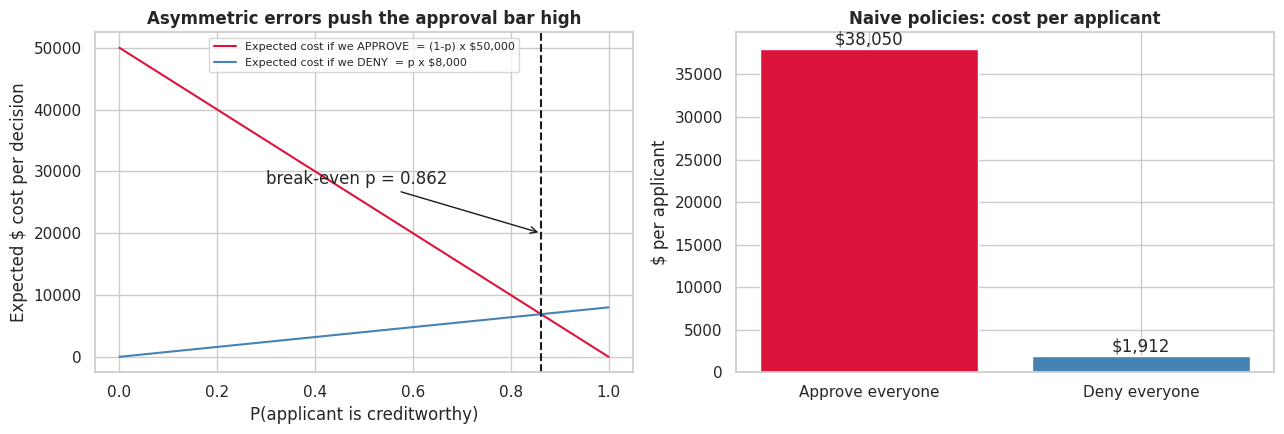

In [4]:
# Visual: expected cost of each decision as a function of P(applicant is creditworthy)
p = np.linspace(0, 1, 200)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(p, (1 - p) * COST_FP, label='Expected cost if we APPROVE  = (1-p) x $50,000', color='crimson')
ax[0].plot(p, p * COST_FN, label='Expected cost if we DENY  = p x $8,000', color='steelblue')
ax[0].axvline(BAYES_T, color='k', ls='--'); ax[0].annotate(f'break-even p = {BAYES_T:.3f}', (BAYES_T, 20000), xytext=(0.30, 28000), arrowprops=dict(arrowstyle='->', color='k'))
ax[0].set_xlabel('P(applicant is creditworthy)'); ax[0].set_ylabel('Expected $ cost per decision'); ax[0].set_title('Asymmetric errors push the approval bar high'); ax[0].legend(loc='upper center', fontsize=8)
ax[1].bar(['Approve everyone', 'Deny everyone'], baseline_df['Cost per applicant ($)'], color=['crimson', 'steelblue'])
for i, v in enumerate(baseline_df['Cost per applicant ($)']): ax[1].text(i, v, f'${v:,.0f}', ha='center', va='bottom')
ax[1].set_title('Naive policies: cost per applicant'); ax[1].set_ylabel('$ per applicant')
plt.tight_layout()


The left chart shows why the bar is so high: the expected loss from approving falls linearly with the probability of being creditworthy, but even at p = 0.8 it is still above the expected loss from denying. The break-even point is 0.862. The right chart shows the two naive policies: approving everyone is catastrophic ($38,050 per applicant), and denying everyone ($1,912) is the bar the model has to beat.

### 2. Modeling goals and success criteria

**Metrics and why**

| Metric | Why it is used |
|---|---|
| **Business cost ($ per applicant)**: *custom metric* = $50,000 × false approvals + $8,000 × false denials | The primary yardstick. It is exactly the business's own cost structure. I also report *net value vs. deny-all* (= $8 k × TP − $50 k × FP) as a profit view of the same number. |
| **ROC-AUC** | Threshold-independent ranking quality: can the model order applicants from riskiest to safest? Used for model comparison and tuning. |
| **PR-AUC (average precision)** | More informative than ROC-AUC with 24 % positives; focuses on the quality of the approved group. |
| **Precision** | Of the applicants we approve, how many are truly good? This is the lever that controls the $50 k errors. |
| **Recall** | Of the good applicants, how many do we capture? This controls the $8 k opportunity cost. |
| **F1** | A single summary of precision and recall, reported for reference only; it weights both errors equally, which the business does *not*. |

**Baseline performance targets** (fixed *before* modelling, relative to the naive policies):


In [5]:
# Baseline performance targets (set BEFORE modelling, relative to the naive policies above)
best_naive_cost = baseline_df['Cost per applicant ($)'].min()
TARGETS = {
    'ROC-AUC (ranking quality)': '>= 0.90 minimum, >= 0.95 stretch',
    'Precision of approvals (share of approvals that are truly good)': '>= 0.90',
    'Recall of good applicants': '>= 0.60 (we can afford to miss some good loans)',
    'Cost per applicant ($)': f'<= {0.5*best_naive_cost:,.0f}  (at least 50% below the best naive policy, which is {best_naive_cost:,.0f})',
}
pd.Series(TARGETS, name='Target').to_frame()


,Target
ROC-AUC (ranking quality),">= 0.90 minimum, >= 0.95 stretch"
Precision of approvals (share of approvals that are truly good),>= 0.90
Recall of good applicants,>= 0.60 (we can afford to miss some good loans)
Cost per applicant ($),<= 956 (at least 50% below the best naive pol...


The cost target is deliberately demanding: the best naive policy is to deny everyone, so the model must prove it earns money on top of that.


## Data Understanding
3. Conduct comprehensive exploratory data analysis:
- Describe basic data characteristics
- Examine distributions of all features and target variables
- Investigate relationships between features
- Create visualizations to help aid in EDA
- Document potential data quality issues and their implications

4. Develop feature understanding:
- Categorize features by type (numerical, categorical, ordinal)
- Identify features requiring special preprocessing
- Document missing value patterns and their potential meanings
- Note potential feature engineering opportunities

### 3a. Basic characteristics and data-quality audit
The data has 20,000 rows and 35 columns: 18 integer columns, 10 floats and 7 text columns, covering demographics, credit history, assets and liabilities, loan terms and two outcome columns (`LoanApproved`, `RiskScore`). There are no duplicate rows.


In [6]:
# First look at the raw data
print(raw.shape)
display(raw.head(3).T.rename(columns=lambda c: f'row {c}'))
raw.info()


(20000, 35)


,row 0,row 1,row 2
Age,45,38,47
AnnualIncome,"$39,948.00","$39,709.00","$40,724.00"
CreditScore,617,628,570
EmploymentStatus,Employed,Employed,Employed
EducationLevel,Master,Associate,Bachelor
Experience,22,15,26
LoanAmount,13152,26045,17627
LoanDuration,48,48,36
MaritalStatus,Married,Single,NaN
NumberOfDependents,2,1,2


<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   AnnualIncome                20000 non-null  str    
 2   CreditScore                 20000 non-null  int64  
 3   EmploymentStatus            20000 non-null  str    
 4   EducationLevel              19099 non-null  str    
 5   Experience                  20000 non-null  int64  
 6   LoanAmount                  20000 non-null  int64  
 7   LoanDuration                20000 non-null  int64  
 8   MaritalStatus               18669 non-null  str    
 9   NumberOfDependents          20000 non-null  int64  
 10  HomeOwnershipStatus         20000 non-null  str    
 11  MonthlyDebtPayments         20000 non-null  int64  
 12  CreditCardUtilizationRate   20000 non-null  float64
 13  NumberOfOpenCreditLines     20000 non-null

In [7]:
# ---------- Data-quality audit on the RAW file (descriptive only: nothing is learned from the data here) ----------
print('Duplicate rows:', raw.duplicated().sum())

miss = pd.DataFrame({'missing_n': raw.isna().sum(), 'missing_pct': raw.isna().mean() * 100})
display(miss[miss.missing_n > 0].round(2))

# AnnualIncome is stored as TEXT like "$39,948.00"
print('\nAnnualIncome dtype:', raw['AnnualIncome'].dtype, '| example:', raw['AnnualIncome'].iloc[0])
income_reported = raw['AnnualIncome'].astype(str).str.replace(r'[\$,]', '', regex=True).astype(float)

# Consistency check: AnnualIncome should equal 12 x MonthlyIncome
gap = income_reported - 12 * raw['MonthlyIncome']
mismatch = gap.abs() > 1
print(f'\nRows where AnnualIncome != 12 x MonthlyIncome: {mismatch.sum()} ({mismatch.mean():.2%})')
print('Ratio reported/implied annual income in those rows:'); print((income_reported[mismatch] / (12 * raw['MonthlyIncome'][mismatch])).describe().round(3).to_string())

# Other logical checks
print('\nExperience > Age-18 :', (raw['Experience'] > raw['Age'] - 18).sum())
print('TotalAssets < Savings+Checking :', (raw['TotalAssets'] < raw['SavingsAccountBalance'].fillna(0) + raw['CheckingAccountBalance']).sum())
print('NetWorth != Assets-Liabilities (floored at $1,000 by construction):', (raw['NetWorth'] != raw['TotalAssets'] - raw['TotalLiabilities']).sum())
print('Credit score range:', raw['CreditScore'].min(), '-', raw['CreditScore'].max())

# Category label audit
for c in ['EmploymentStatus', 'EducationLevel', 'MaritalStatus', 'HomeOwnershipStatus', 'BankruptcyHistory', 'LoanPurpose']:
    print(f'{c}:', raw[c].value_counts(dropna=False).to_dict())


Duplicate rows: 0


,missing_n,missing_pct
EducationLevel,901,4.50
MaritalStatus,1331,6.65
SavingsAccountBalance,572,2.86



AnnualIncome dtype: str | example: $39,948.00

Rows where AnnualIncome != 12 x MonthlyIncome: 195 (0.97%)
Ratio reported/implied annual income in those rows:
count    195.000
mean       1.767
std        0.148
min        1.500
25%        1.638
50%        1.779
75%        1.893
max        2.000

Experience > Age-18 : 0
TotalAssets < Savings+Checking : 0
NetWorth != Assets-Liabilities (floored at $1,000 by construction): 4801
Credit score range: 343 - 712
EmploymentStatus: {'Employed': 17036, 'Self-Employed': 1573, 'Unemployed': 1391}
EducationLevel: {'Bachelor': 5804, 'High School': 5592, 'Associate': 3850, 'Master': 2933, 'Doctorate': 920, nan: 901}
MaritalStatus: {'Married': 9370, 'Single': 5665, 'Divorced': 2704, nan: 1331, 'Widowed': 930}
HomeOwnershipStatus: {'Mortgage': 7939, 'Rent': 6087, 'Own': 3938, 'Other': 2036}
BankruptcyHistory: {'No': 18952, 'Yes': 1048}
LoanPurpose: {'Home': 5925, 'Debt Consolidation': 5027, 'Auto': 4034, 'Education': 3008, 'Other': 2006}


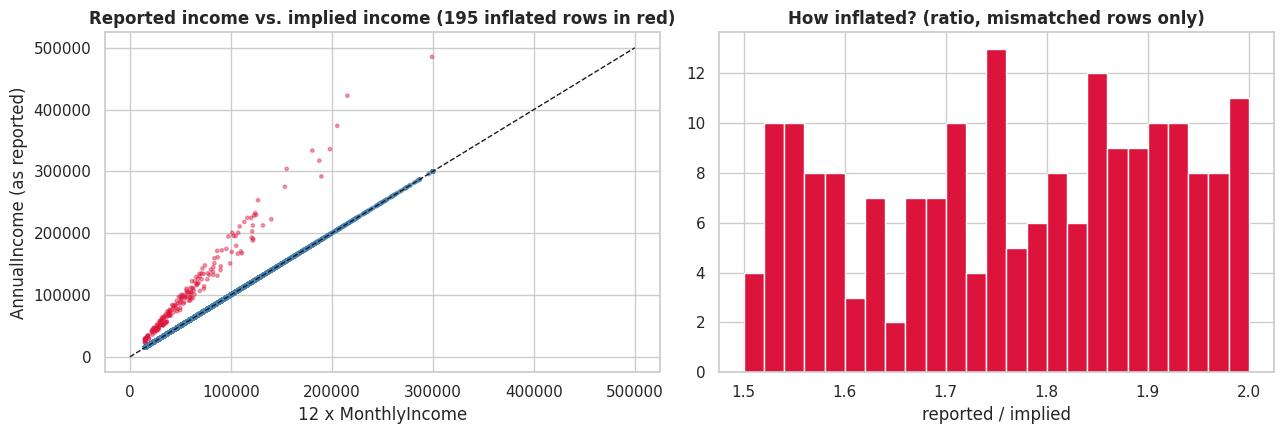

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(12 * raw['MonthlyIncome'], income_reported, s=6, alpha=.4, c=np.where(mismatch, 'crimson', 'steelblue'))
lim = [0, 5e5]; ax[0].plot(lim, lim, 'k--', lw=1); ax[0].set_xlabel('12 x MonthlyIncome'); ax[0].set_ylabel('AnnualIncome (as reported)')
ax[0].set_title(f'Reported income vs. implied income ({mismatch.sum()} inflated rows in red)')
ax[1].hist(income_reported[mismatch] / (12 * raw['MonthlyIncome'][mismatch]), bins=25, color='crimson'); ax[1].set_title('How inflated? (ratio, mismatched rows only)'); ax[1].set_xlabel('reported / implied')
plt.tight_layout()


**Data-quality issues found, and what I do about each**

| Issue | Evidence | Implication / handling |
|---|---|---|
| `AnnualIncome` stored as text (`"$39,948.00"`) | `dtype` is string | Strip `$` and `,` and convert to float (stateless cleaning step). |
| **Inflated incomes** | 195 rows (0.97 %) where `AnnualIncome` is 1.5×–2.0× `12 × MonthlyIncome` | Looks like data-entry corruption. `MonthlyIncome` is internally consistent, so it is used and `AnnualIncome` is dropped (they correlate at 0.99 anyway). |
| Missing values | `EducationLevel` 4.5 %, `MaritalStatus` 6.7 %, `SavingsAccountBalance` 2.9 % | Handled per feature type, with missing-value flags (see below). |
| `NetWorth` ≠ Assets − Liabilities in about 24 % of rows | `NetWorth` has a hard minimum of $1,000 | Consistent with a floor on net worth; kept as is. |
| Heavy right tails | skew of 5–6 for balances, assets and liabilities | Log transform and winsorising inside the pipeline. |
| Credit scores only run from 343 to 712 | no applicants above 712 | Unusually narrow; noted as a limitation on generalisation. |
| **Target leakage risk** | `RiskScore` is lower for approved applicants by construction (see below) | Excluded from classification features. |


### Train / test split
I split off a **20 % stratified hold-out test set** (4,000 rows) *before* any exploration that could influence modelling. EDA is done on the 16,000 training rows only, and everything the pipeline learns (medians, scaling, clipping bounds, encodings) is fitted on training folds only. Cleaning that learns nothing (parsing text, mapping Yes/No) is applied up front.


In [9]:
# ---------- Stateless cleaning (no statistics are learned here, so it is safe to do before the split) ----------
def clean_raw(df):
    df = df.copy()
    df['AnnualIncome'] = df['AnnualIncome'].astype(str).str.replace(r'[\$,]', '', regex=True).astype(float)   # "$39,948.00" -> 39948.0
    df['BankruptcyHistory'] = df['BankruptcyHistory'].map({'No': 0, 'Yes': 1}).astype(int)                    # binary text -> 0/1
    for c in df.columns:                                                                                       # plain object dtype keeps sklearn imputers happy across pandas versions
        if df[c].dtype == 'object' or str(df[c].dtype).startswith('str'):
            df[c] = df[c].astype(object)
    return df

df = clean_raw(raw)

# Targets: LoanApproved (classification). RiskScore is kept aside ONLY for the regression comparison later
# (it is excluded from the classification features - see the leakage discussion in the EDA).
TARGET = 'LoanApproved'
X = df.drop(columns=[TARGET, 'RiskScore'])
y = df[TARGET]
risk = df['RiskScore']

# Hold-out test set: 20 %, stratified so the 23.9 % approval rate is preserved. Untouched until final evaluation.
X_train, X_test, y_train, y_test, risk_train, risk_test = train_test_split(
    X, y, risk, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows')
print(f'Approval rate  train: {y_train.mean():.3%}   test: {y_test.mean():.3%}')

# EDA is done on the TRAINING portion only so that no modelling decision is influenced by the test set
eda = X_train.copy(); eda[TARGET] = y_train; eda['RiskScore'] = risk_train


Train: 16,000 rows | Test: 4,000 rows
Approval rate  train: 23.900%   test: 23.900%


### 4a. Feature types


In [10]:
# ---------- Feature typing ----------
ordinal_cols = ['EducationLevel']
nominal_cols = ['EmploymentStatus', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose']
binary_cols  = ['BankruptcyHistory', 'PreviousLoanDefaults']
numeric_cols = [c for c in X_train.columns if c not in ordinal_cols + nominal_cols + binary_cols]
money_cols   = ['AnnualIncome', 'MonthlyIncome', 'LoanAmount', 'MonthlyDebtPayments', 'SavingsAccountBalance', 'CheckingAccountBalance',
                'TotalAssets', 'TotalLiabilities', 'NetWorth', 'MonthlyLoanPayment']

ftype = {}
for c in numeric_cols: ftype[c] = 'numerical (money/skewed)' if c in money_cols else ('numerical (rate/ratio)' if X_train[c].between(0, 5).all() and X_train[c].dtype == float else 'numerical (count/score)')
for c in ordinal_cols: ftype[c] = 'ordinal'
for c in nominal_cols: ftype[c] = 'categorical (nominal)'
for c in binary_cols:  ftype[c] = 'binary'

summary = pd.DataFrame({'type': pd.Series(ftype), 'dtype': X_train.dtypes.astype(str), 'n_unique': X_train.nunique(),
                        'missing_%': (X_train.isna().mean() * 100).round(2)})
summary['skew'] = X_train[numeric_cols].skew().round(2)
summary = summary.loc[X_train.columns]
display(summary)
print('\nCounts by type:'); print(summary['type'].value_counts().to_string())


,type,dtype,n_unique,missing_%,skew
Age,numerical (count/score),int64,63,0.00,0.18
AnnualIncome,numerical (money/skewed),float64,14307,0.00,2.08
CreditScore,numerical (count/score),int64,318,0.00,-0.60
EmploymentStatus,categorical (nominal),object,3,0.00,NaN
EducationLevel,ordinal,object,5,4.42,NaN
Experience,numerical (count/score),int64,62,0.00,0.34
LoanAmount,numerical (money/skewed),int64,13032,0.00,1.88
LoanDuration,numerical (count/score),int64,10,0.00,0.65
MaritalStatus,categorical (nominal),object,4,6.65,NaN
NumberOfDependents,numerical (count/score),int64,6,0.00,0.64



Counts by type:
type
numerical (count/score)     10
numerical (money/skewed)    10
numerical (rate/ratio)       6
categorical (nominal)        4
binary                       2
ordinal                      1


There are **26 numeric features** (10 skewed money-type fields, 6 rates/ratios, 10 counts/scores), **4 nominal categoricals** (`EmploymentStatus`, `MaritalStatus`, `HomeOwnershipStatus`, `LoanPurpose`), **1 ordinal** (`EducationLevel`: High School < Associate < Bachelor < Master < Doctorate) and **2 binary** flags (`BankruptcyHistory`, `PreviousLoanDefaults`). The money fields need a log transform, the ordinal needs an ordered encoding, and the nominals need one-hot encoding.

### 3b. Target distribution and class imbalance


Imbalance ratio (denied : approved) = 3.18 : 1


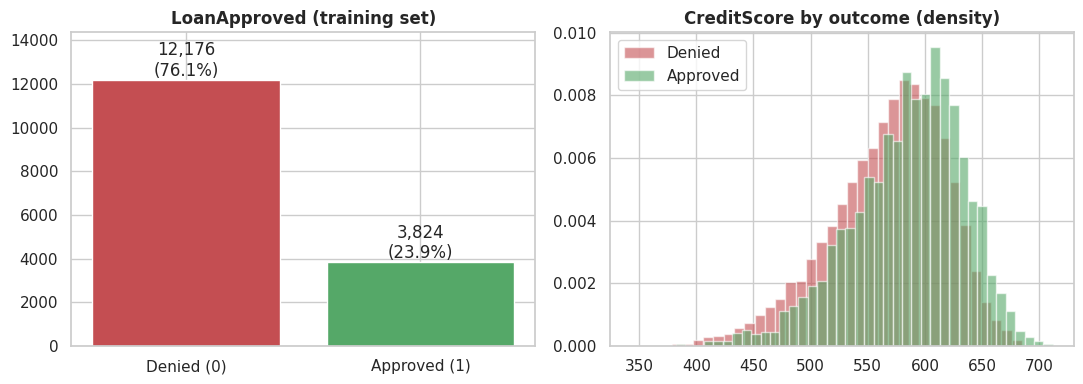

In [11]:
# ---------- Target distribution / class imbalance ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = y_train.value_counts().sort_index()
ax[0].bar(['Denied (0)', 'Approved (1)'], counts.values, color=['#c44e52', '#55a868'])
for i, v in enumerate(counts.values): ax[0].text(i, v, f'{v:,}\n({v/len(y_train):.1%})', ha='center', va='bottom')
ax[0].set_title('LoanApproved (training set)'); ax[0].set_ylim(0, counts.max() * 1.18)
ax[1].hist(eda.loc[eda.LoanApproved == 0, 'CreditScore'], bins=40, alpha=.6, label='Denied', color='#c44e52', density=True)
ax[1].hist(eda.loc[eda.LoanApproved == 1, 'CreditScore'], bins=40, alpha=.6, label='Approved', color='#55a868', density=True)
ax[1].set_title('CreditScore by outcome (density)'); ax[1].legend()
plt.tight_layout()
print(f'Imbalance ratio (denied : approved) = {counts[0]/counts[1]:.2f} : 1')


Only **23.9 %** of applications are approved (3.2 : 1 imbalance). This is moderate: it makes accuracy misleading and means the default 0.5 probability cut-off is not appropriate, but it is not extreme enough to need resampling. The imbalance is handled where it belongs, in the *decision threshold* chosen from the business costs (and `class_weight` is tested during tuning).

### 3c. Univariate distributions


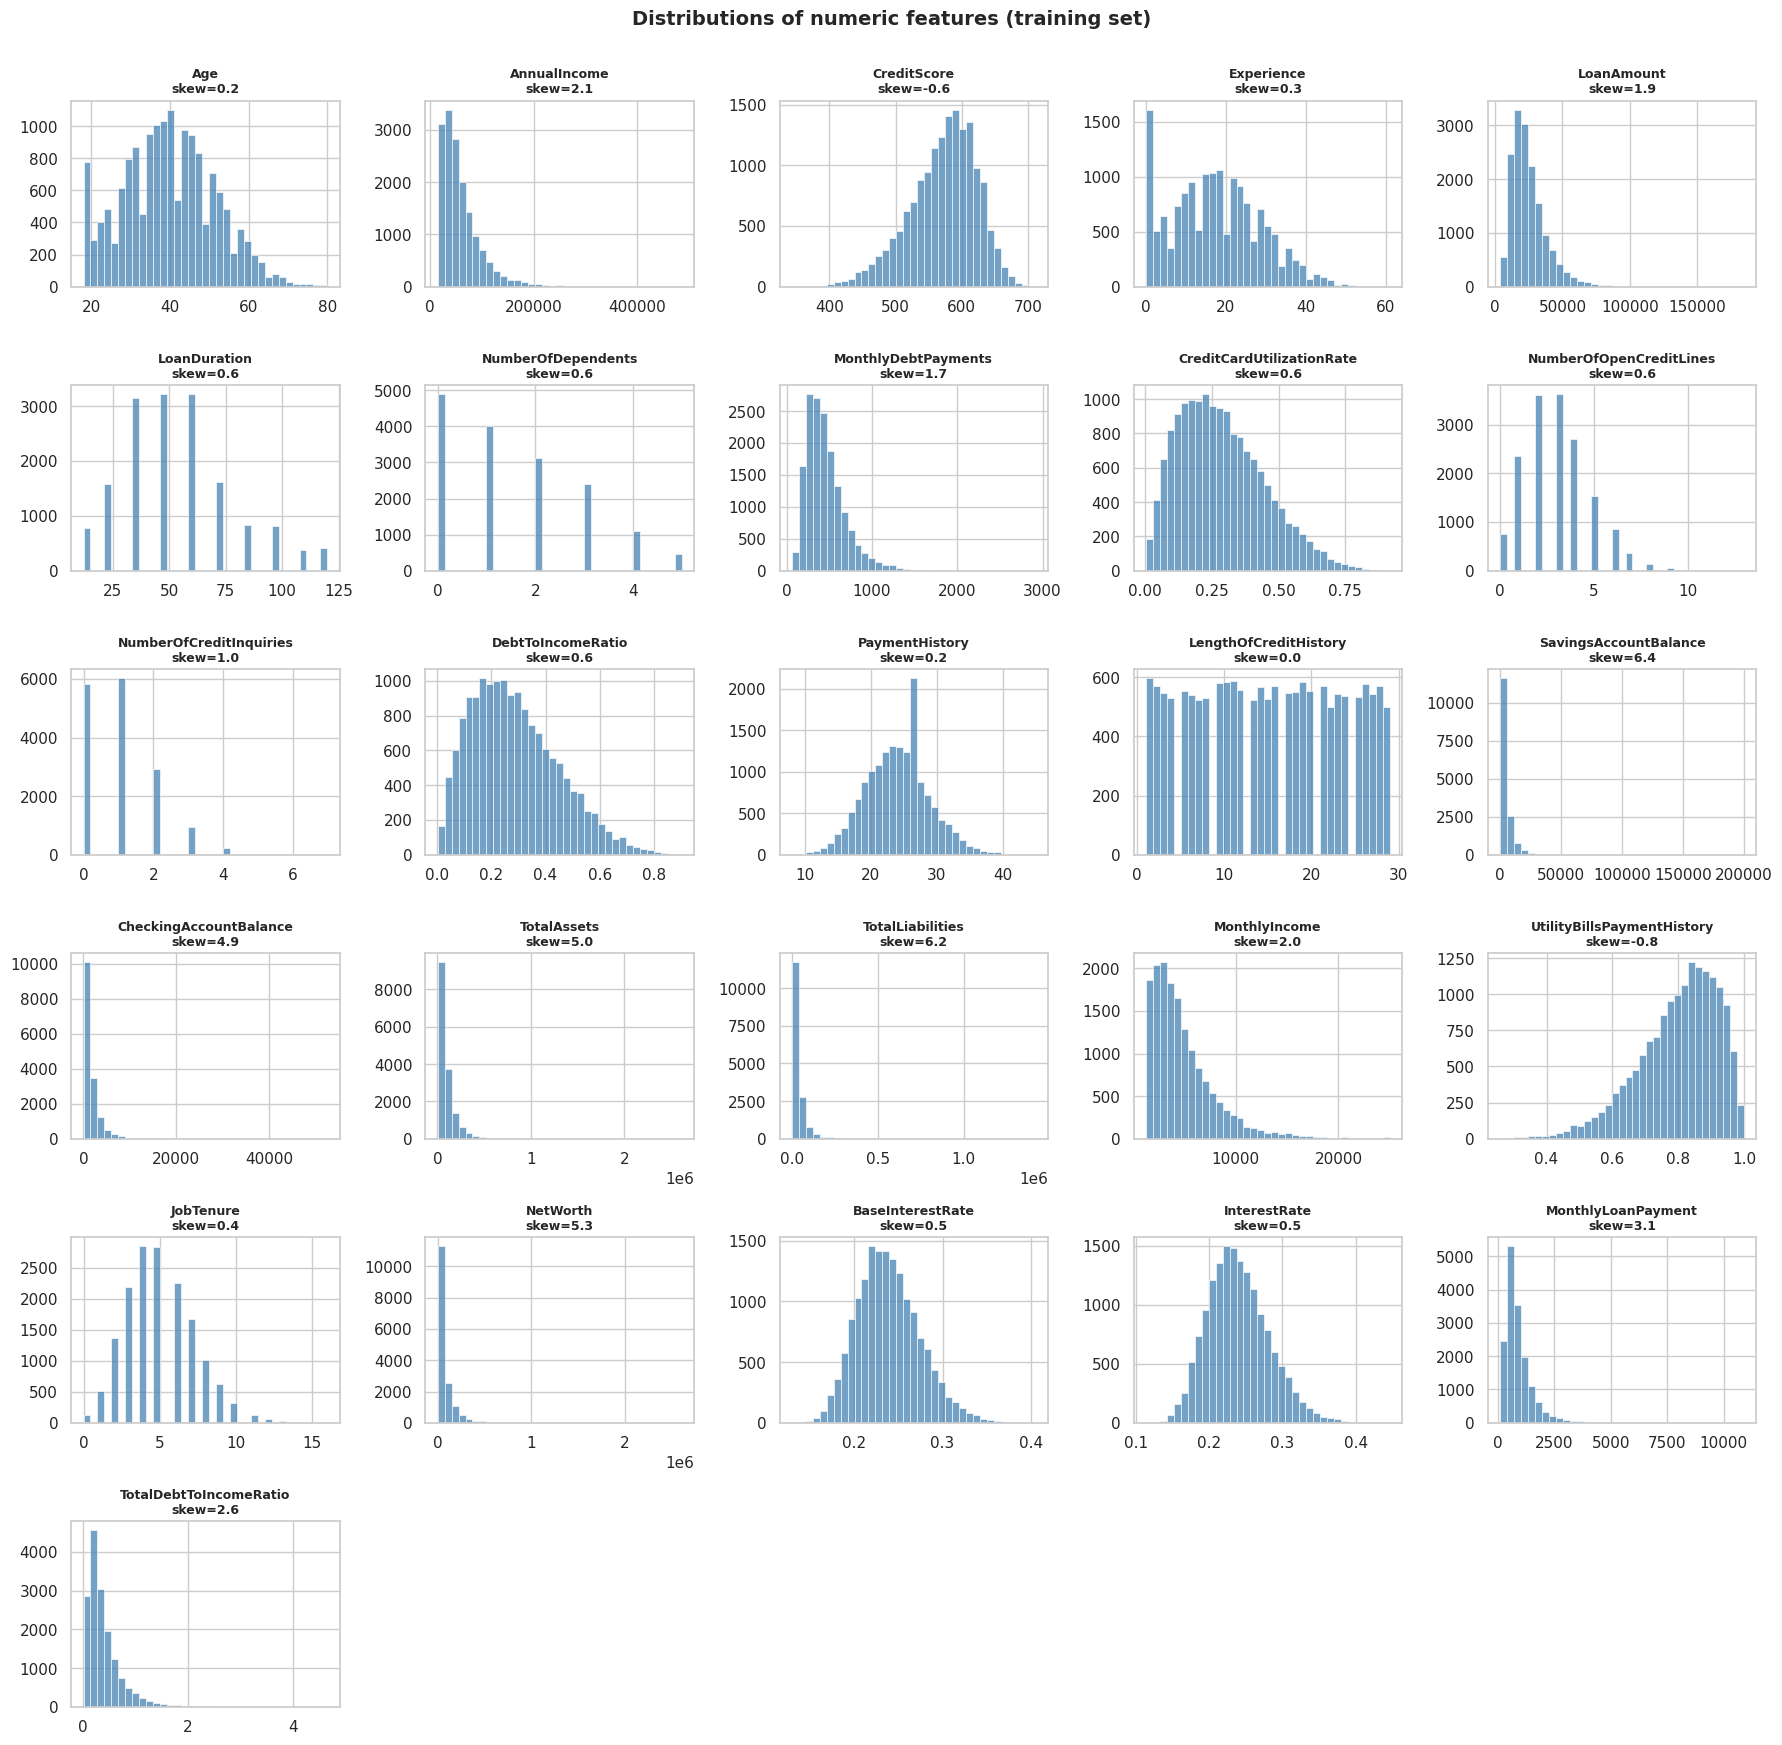

In [12]:
# ---------- Univariate: distributions of every numeric feature ----------
plot_cols = numeric_cols
n = len(plot_cols); ncols = 5; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 2.9 * nrows))
for ax, c in zip(axes.ravel(), plot_cols):
    sns.histplot(eda[c].dropna(), bins=35, ax=ax, color='steelblue', edgecolor=None)
    ax.set_title(f'{c}\nskew={eda[c].skew():.1f}', fontsize=9); ax.set_xlabel(''); ax.set_ylabel('')
for ax in axes.ravel()[n:]: ax.axis('off')
plt.suptitle('Distributions of numeric features (training set)', y=1.002, fontsize=14, fontweight='bold')
plt.tight_layout()


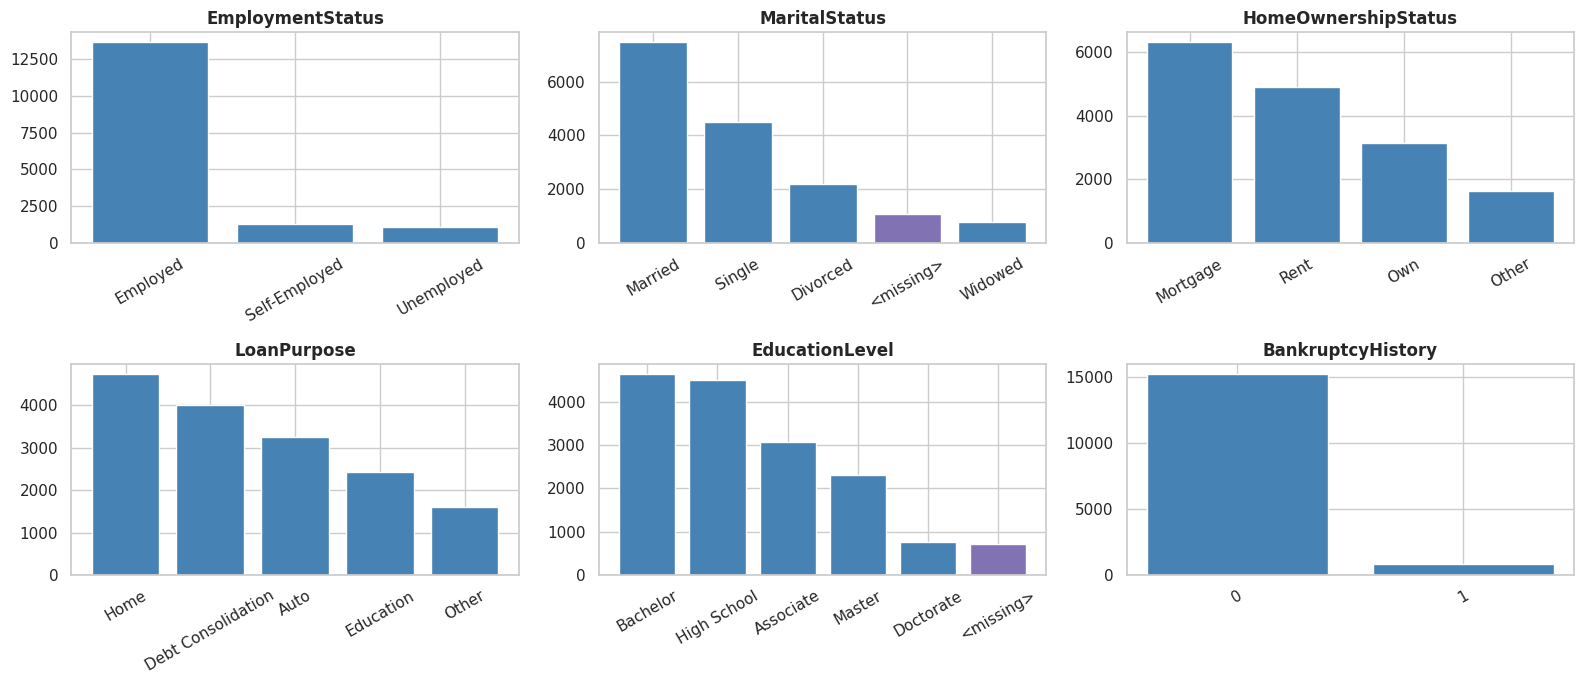

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, c in zip(axes.ravel(), nominal_cols + ordinal_cols + ['BankruptcyHistory']):
    vc = eda[c].value_counts(dropna=False)
    labels = ['<missing>' if (isinstance(i, float) and np.isnan(i)) else str(i) for i in vc.index]
    ax.bar(labels, vc.values, color=['#8172b3' if l == '<missing>' else 'steelblue' for l in labels])
    ax.set_title(c); ax.tick_params(axis='x', rotation=30)
plt.tight_layout()


Money-type variables (`AnnualIncome`, `MonthlyIncome`, `LoanAmount`, balances, assets, liabilities, `NetWorth`) are strongly right-skewed (skew 1.7–6.4). `CreditScore` and `PaymentHistory` are roughly bell-shaped, `LengthOfCreditHistory` is nearly uniform, and several fields are discrete counts. Categories are well populated (smallest: Doctorate at about 5 %), so no rare-level merging is needed.

### 3d. Outliers


,n_outliers,pct,max / median
SavingsAccountBalance,1250,7.81,67.0
NetWorth,1246,7.79,78.9
CheckingAccountBalance,1213,7.58,47.1
TotalLiabilities,1204,7.52,63.9
TotalAssets,1163,7.27,42.9
TotalDebtToIncomeRatio,922,5.76,15.4
MonthlyLoanPayment,888,5.55,14.9
AnnualIncome,768,4.80,10.0
MonthlyIncome,750,4.69,6.2
MonthlyDebtPayments,601,3.76,7.2


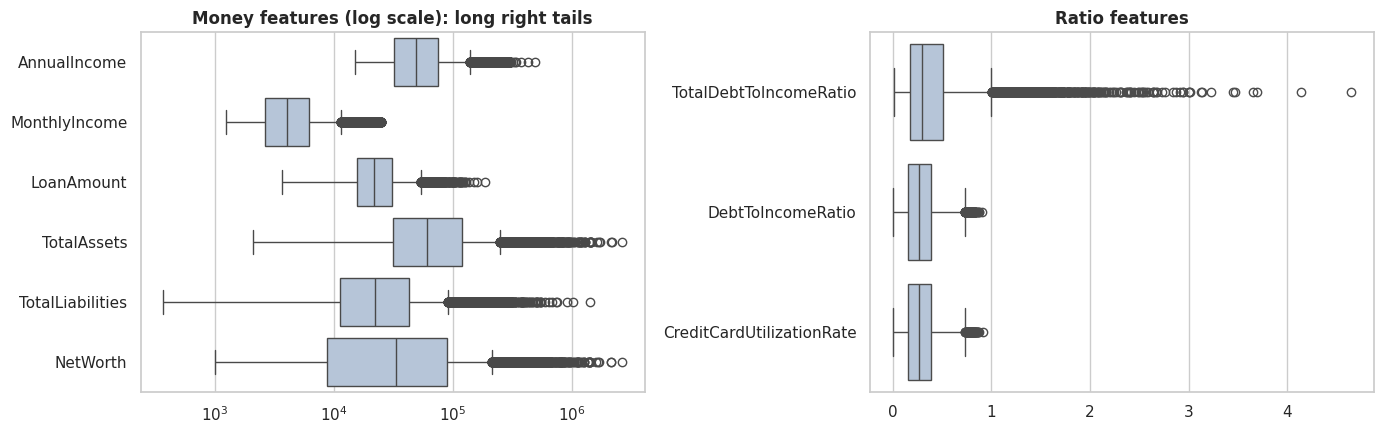

In [14]:
# ---------- Outliers (IQR rule) ----------
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()
out_tbl = pd.DataFrame({'n_outliers': [iqr_outliers(eda[c]) for c in numeric_cols]}, index=numeric_cols)
out_tbl['pct'] = (out_tbl['n_outliers'] / len(eda) * 100).round(2)
out_tbl['max / median'] = (eda[numeric_cols].max() / eda[numeric_cols].median().replace(0, np.nan)).round(1)
display(out_tbl.sort_values('pct', ascending=False).head(12))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=eda[['AnnualIncome', 'MonthlyIncome', 'LoanAmount', 'TotalAssets', 'TotalLiabilities', 'NetWorth']], orient='h', ax=ax[0], color='lightsteelblue')
ax[0].set_xscale('log'); ax[0].set_title('Money features (log scale): long right tails')
sns.boxplot(data=eda[['TotalDebtToIncomeRatio', 'DebtToIncomeRatio', 'CreditCardUtilizationRate']], orient='h', ax=ax[1], color='lightsteelblue')
ax[1].set_title('Ratio features')
plt.tight_layout()


The IQR rule flags 7–8 % of rows for balances and net worth, 5–6 % for the debt-to-income ratio and the loan payment, and 4–5 % for income. These are *plausible long tails* in financial data, not errors, so they are **kept** and tamed with a log transform plus mild winsorising (1st/99th percentile, learned on training folds) rather than deleted. The only values treated as errors are the 195 inflated incomes above.

### 3e. Relationships with the outcome


Correlation with LoanApproved (top 12 numeric):
MonthlyIncome             0.605
AnnualIncome              0.598
TotalDebtToIncomeRatio   -0.409
InterestRate             -0.301
BaseInterestRate         -0.248
LoanAmount               -0.239
NetWorth                  0.187
TotalAssets               0.184
MonthlyLoanPayment       -0.183
CreditScore               0.142
Age                       0.140
Experience                0.139


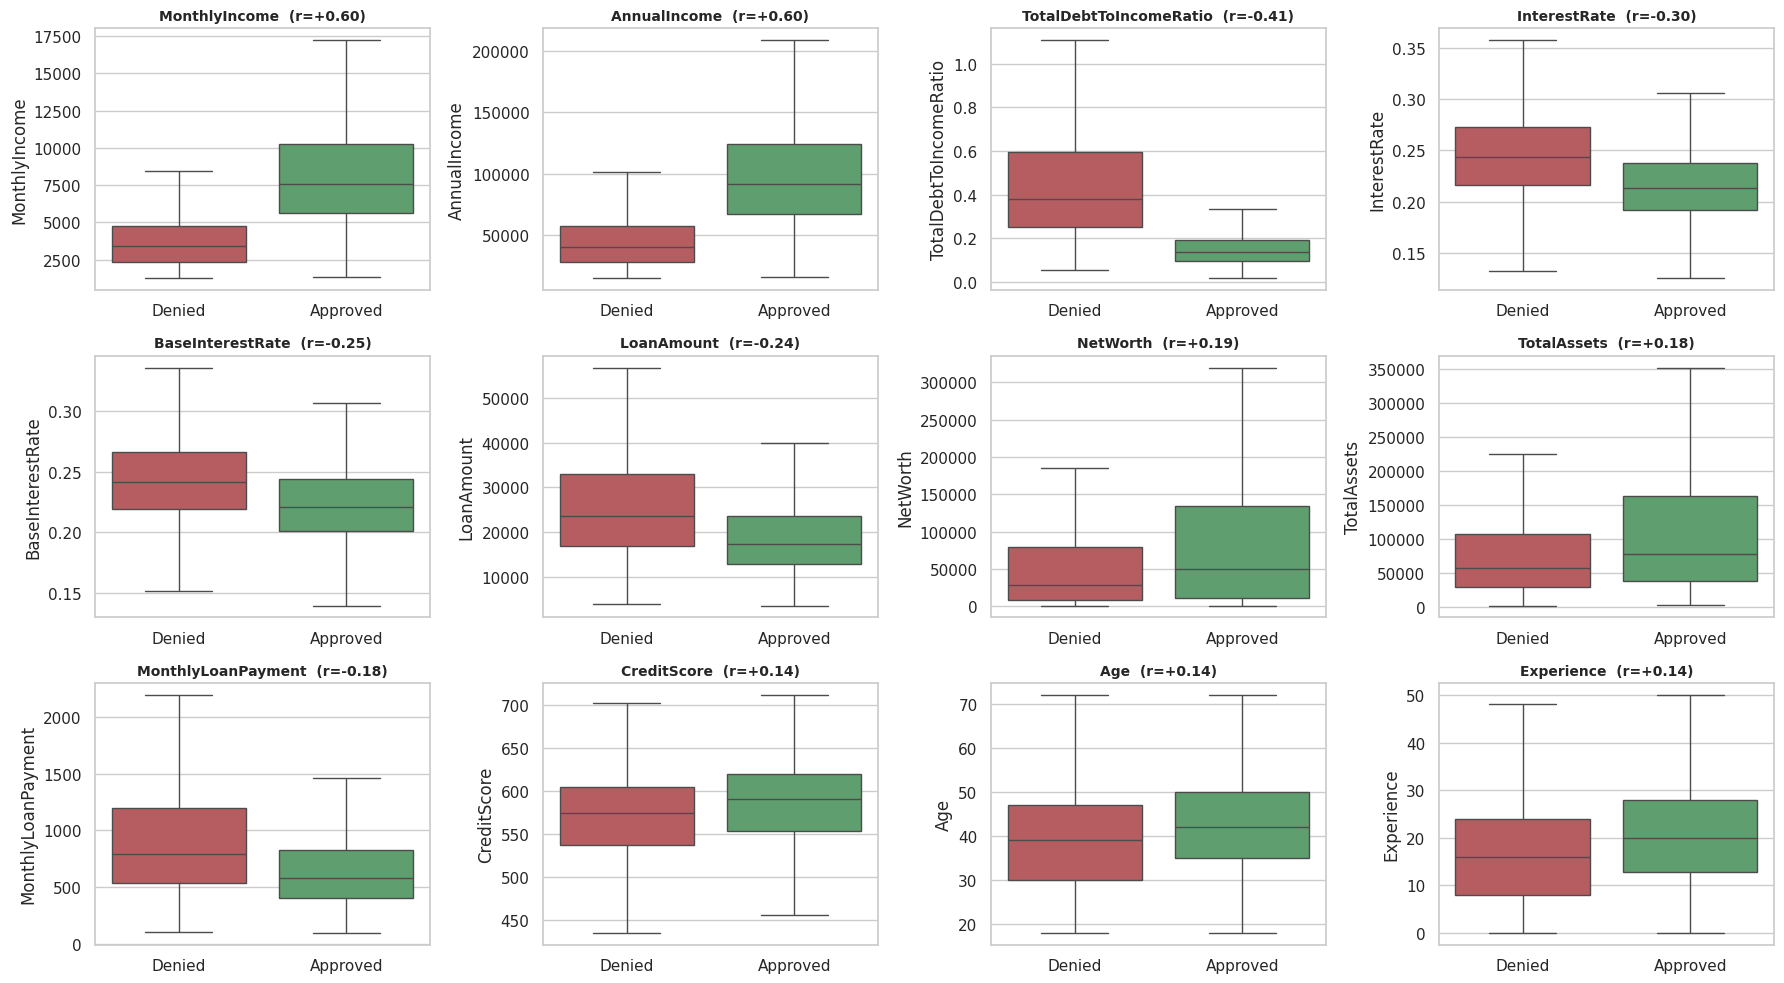

In [15]:
# ---------- Bivariate: numeric features vs outcome ----------
num_corr = eda[numeric_cols + binary_cols].corrwith(eda[TARGET]).sort_values(key=np.abs, ascending=False)
top_num = [c for c in num_corr.index if c not in binary_cols][:12]
print('Correlation with LoanApproved (top 12 numeric):'); print(num_corr.loc[top_num].round(3).to_string())
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, c in zip(axes.ravel(), top_num):
    sns.boxplot(data=eda, x=TARGET, y=c, ax=ax, palette=['#c44e52', '#55a868'], showfliers=False)
    ax.set_xticklabels(['Denied', 'Approved']); ax.set_xlabel(''); ax.set_title(f'{c}  (r={num_corr[c]:+.2f})', fontsize=10)
plt.tight_layout()


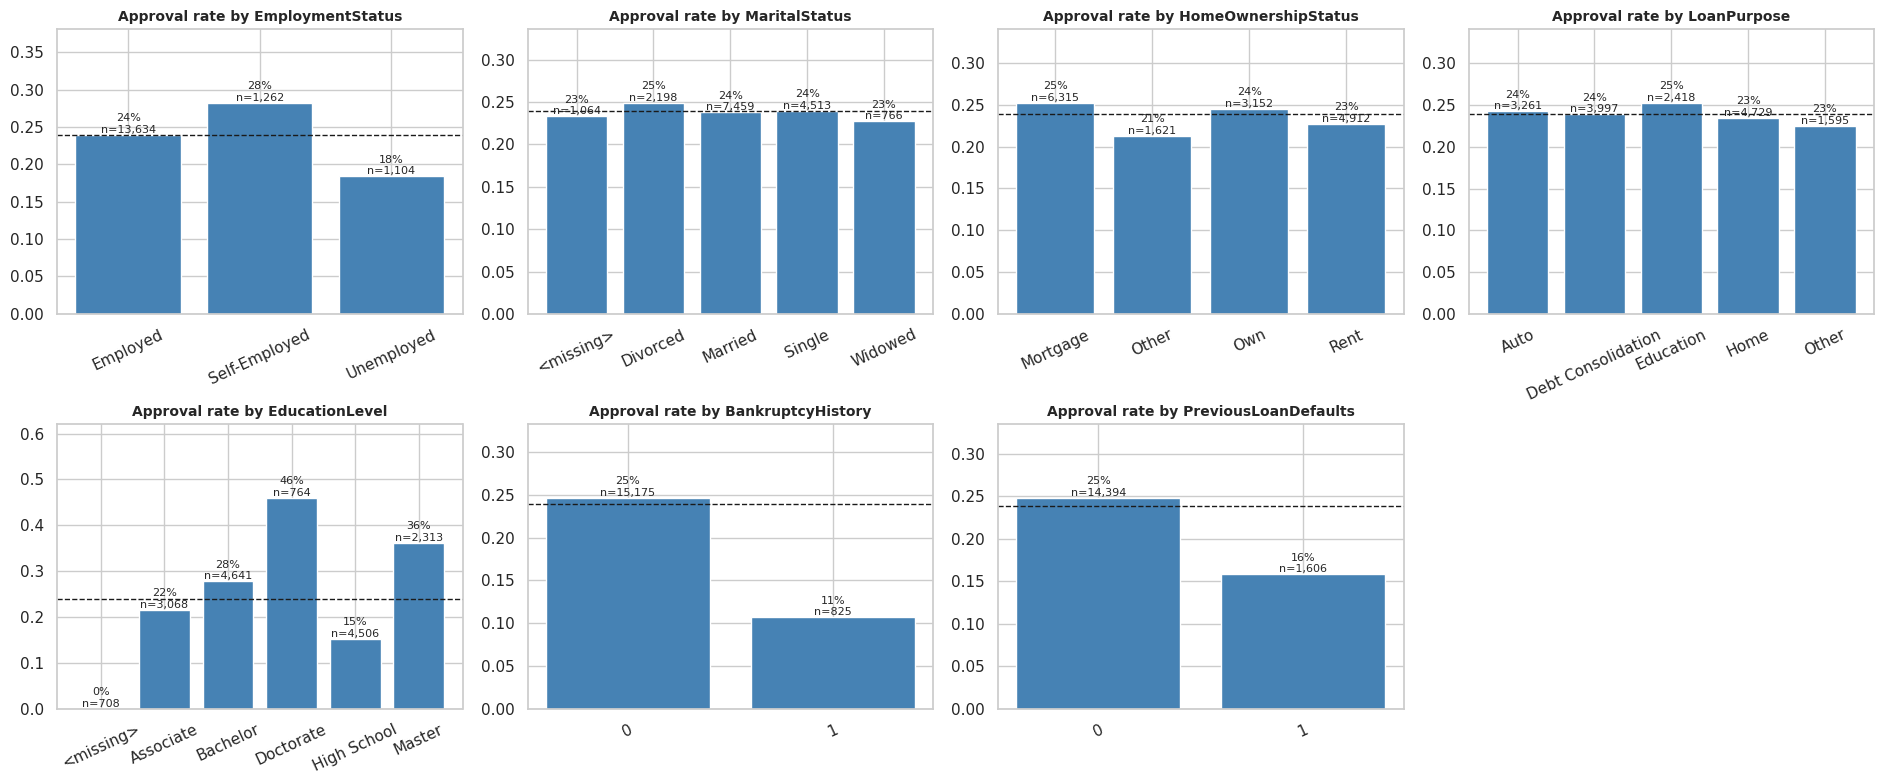

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
overall = eda[TARGET].mean()
for ax, c in zip(axes.ravel(), nominal_cols + ordinal_cols + binary_cols + ['_']):
    if c == '_': ax.axis('off'); continue
    rate = eda.assign(_c=eda[c].astype(object).where(eda[c].notna(), '<missing>')).groupby('_c')[TARGET].agg(['mean', 'size'])
    ax.bar(rate.index.astype(str), rate['mean'], color='steelblue'); ax.axhline(overall, color='k', ls='--', lw=1)
    for i, (m, s) in enumerate(zip(rate['mean'], rate['size'])): ax.text(i, m, f'{m:.0%}\nn={s:,}', ha='center', va='bottom', fontsize=8)
    ax.set_ylim(0, max(rate['mean'].max() * 1.35, .1)); ax.set_title(f'Approval rate by {c}', fontsize=10); ax.tick_params(axis='x', rotation=25)
plt.tight_layout()


Approved applicants have a much higher income (median monthly income $7,578 vs. $3,382), a lower total debt-to-income ratio (0.14 vs. 0.38), a lower interest rate and smaller loans. Approval is strongly related to education level (Doctorate holders are approved roughly 40 % of the time vs. about 15 % for High School), and the Employed/Self-employed groups are approved more often than the Unemployed. Interestingly, the supplied `DebtToIncomeRatio` shows *no* relationship with approval, whereas `TotalDebtToIncomeRatio` (which includes the new loan's payment) is the second-strongest numeric signal (r = −0.41). The lender's decision evidently looks at the burden *after* the new loan.

### 4c. Missing-value patterns


Columns with missing values: ['EducationLevel', 'MaritalStatus', 'SavingsAccountBalance']


,approval rate | missing,approval rate | present,n missing
feature,,,
EducationLevel,0.0000,0.2501,708
MaritalStatus,0.2331,0.2394,1064
SavingsAccountBalance,0.2610,0.2384,456


EducationLevel         missing-vs-approved Fisher exact p = 1.21e-86
MaritalStatus          missing-vs-approved Fisher exact p = 6.55e-01
SavingsAccountBalance  missing-vs-approved Fisher exact p = 2.65e-01

Median MonthlyIncome | SavingsAccountBalance missing vs present: {False: 4042.0, True: 4086.0}


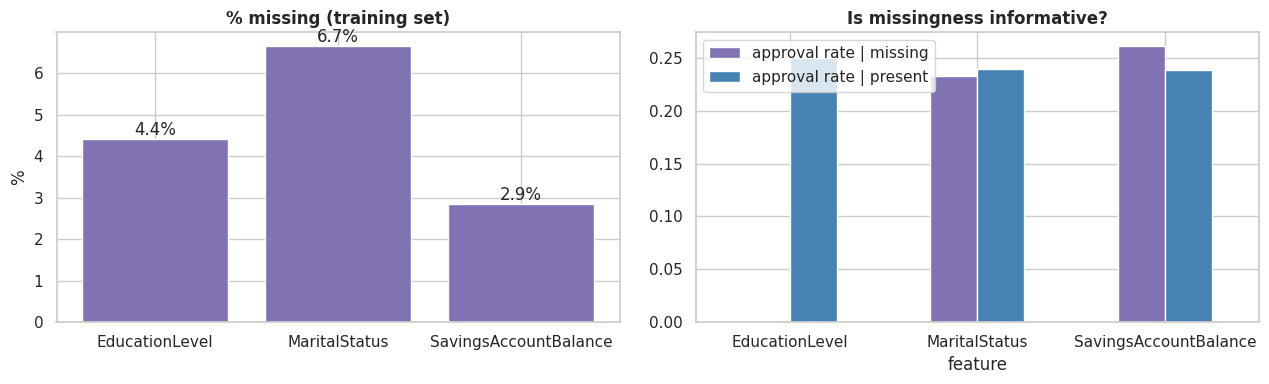

In [17]:
# ---------- Missing-value patterns ----------
miss_cols = [c for c in X_train.columns if X_train[c].isna().any()]
print('Columns with missing values:', miss_cols)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
mp = (eda[miss_cols].isna().mean() * 100); ax[0].bar(mp.index, mp.values, color='#8172b3'); ax[0].set_title('% missing (training set)'); ax[0].set_ylabel('%')
for i, v in enumerate(mp.values): ax[0].text(i, v, f'{v:.1f}%', ha='center', va='bottom')
rows = []
for c in miss_cols:
    m = eda[c].isna()
    rows.append({'feature': c, 'approval rate | missing': eda.loc[m, TARGET].mean(), 'approval rate | present': eda.loc[~m, TARGET].mean(), 'n missing': int(m.sum())})
mt = pd.DataFrame(rows).set_index('feature')
mt[['approval rate | missing', 'approval rate | present']].plot.bar(ax=ax[1], color=['#8172b3', 'steelblue']); ax[1].set_title('Is missingness informative?'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); display(mt.round(4))
# Formal test for each missing flag vs. outcome (Fisher exact, 2x2)
for c in miss_cols:
    tab = pd.crosstab(eda[c].isna(), eda[TARGET])
    odds, pval = stats.fisher_exact(tab.values)
    print(f'{c:22s} missing-vs-approved Fisher exact p = {pval:.2e}')
# Is missingness related to other features? (e.g., does missing Savings relate to income?)
print('\nMedian MonthlyIncome | SavingsAccountBalance missing vs present:', eda.groupby(eda['SavingsAccountBalance'].isna())['MonthlyIncome'].median().round(0).to_dict())


- **`EducationLevel` is missing not at random:** none of the 708 training applicants with a missing education level was approved (vs. 25 % otherwise; Fisher exact p ≈ 10⁻⁸⁶). Missingness is a *signal*, so I keep it as an explicit "was missing" flag rather than silently imputing it away. In a real setting this is more likely a process artifact (incomplete files are rejected) than a genuine credit signal, and I flag that as a business issue.
- `MaritalStatus` (p = 0.66) and `SavingsAccountBalance` (p = 0.27) are missing at random with respect to the outcome. Savings gaps do not depend on income level (median income $4,086 vs. $4,042), so they look like ordinary missing entries.

### 3f. Feature relationships


,feature_a,feature_b,r
0,MonthlyIncome,AnnualIncome,0.989
1,Experience,Age,0.983
2,NetWorth,TotalAssets,0.979
3,InterestRate,BaseInterestRate,0.834


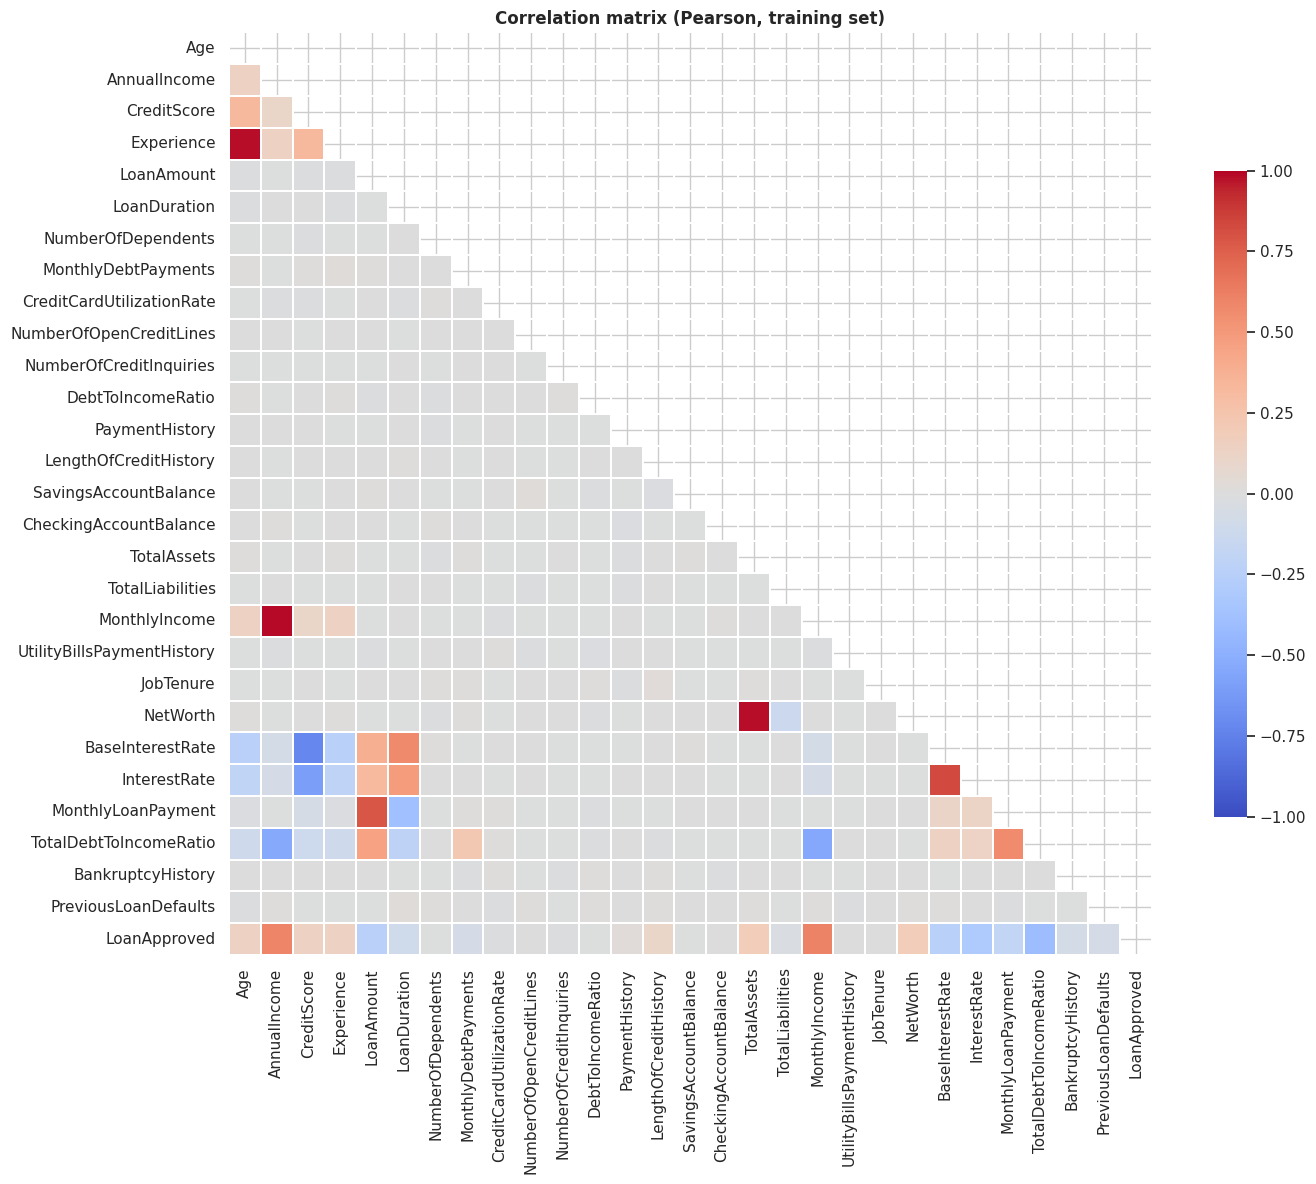

In [18]:
# ---------- Feature relationships ----------
corr = eda[numeric_cols + binary_cols + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, linewidths=.3, cbar_kws={'shrink': .7}, ax=ax)
ax.set_title('Correlation matrix (Pearson, training set)')
plt.tight_layout()
pairs = corr.where(~mask).stack().rename('r').reset_index(); pairs.columns = ['feature_a', 'feature_b', 'r']
display(pairs[pairs.r.abs() > 0.8].sort_values('r', key=np.abs, ascending=False).round(3).reset_index(drop=True))


Text(0.5, 1.01, 'Pair plot of the strongest drivers (1,500-row sample)')

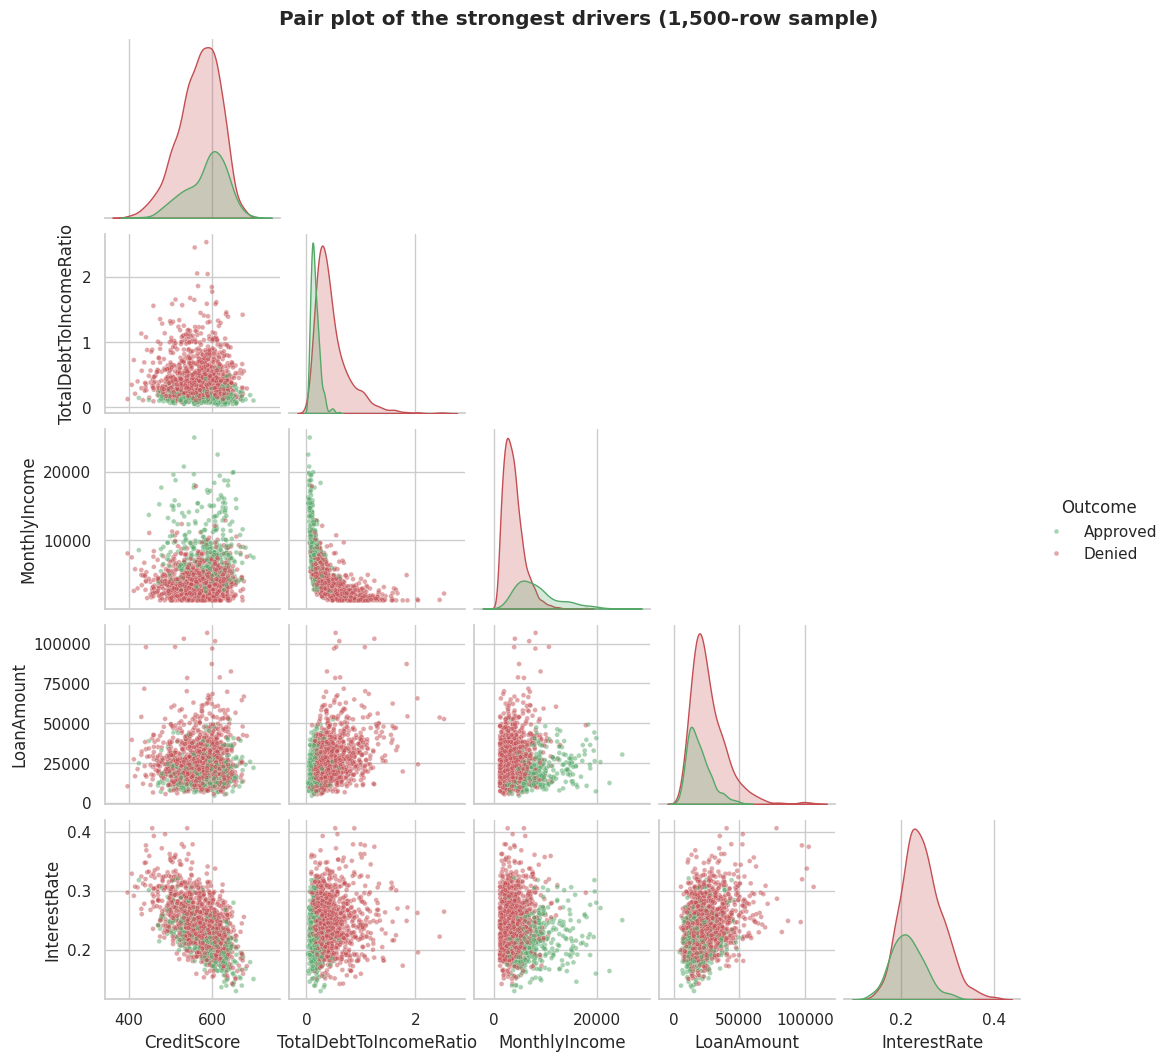

In [19]:
key = ['CreditScore', 'TotalDebtToIncomeRatio', 'MonthlyIncome', 'LoanAmount', 'InterestRate']
sample = eda.sample(1500, random_state=RANDOM_STATE)[key + [TARGET]].copy()
sample['Outcome'] = sample[TARGET].map({0: 'Denied', 1: 'Approved'})
g = sns.pairplot(sample.drop(columns=TARGET), hue='Outcome', palette={'Denied': '#c44e52', 'Approved': '#55a868'}, corner=True, plot_kws={'s': 12, 'alpha': .5}, height=2.1)
g.figure.suptitle('Pair plot of the strongest drivers (1,500-row sample)', y=1.01, fontweight='bold')


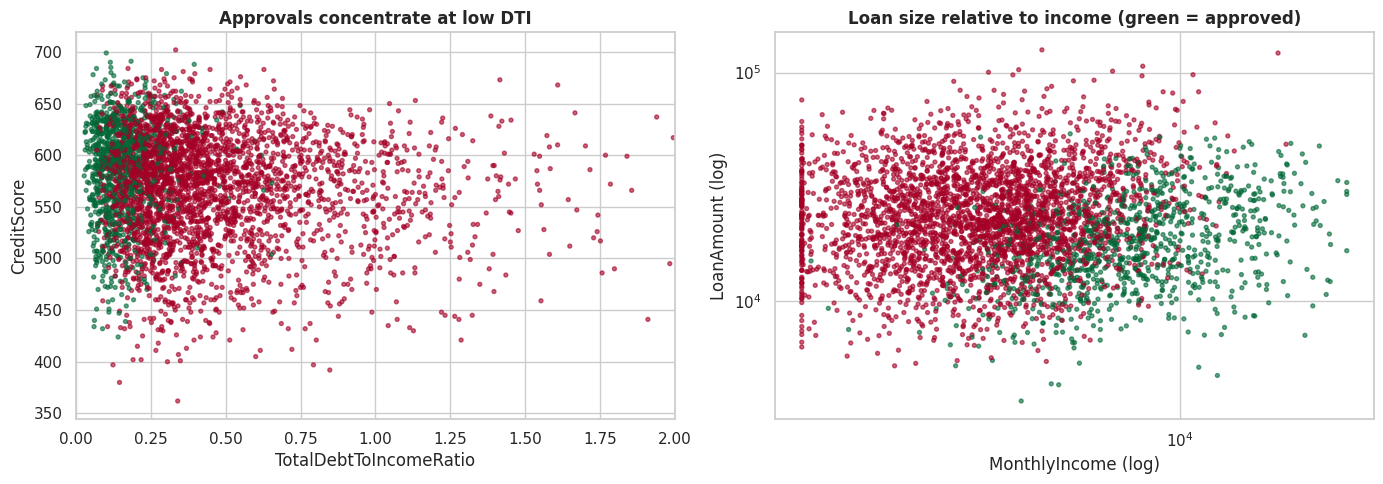

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
s = eda.sample(4000, random_state=RANDOM_STATE)
sc = ax[0].scatter(s['TotalDebtToIncomeRatio'], s['CreditScore'], c=s[TARGET], cmap='RdYlGn', s=8, alpha=.6)
ax[0].set_xlim(0, 2); ax[0].set_xlabel('TotalDebtToIncomeRatio'); ax[0].set_ylabel('CreditScore'); ax[0].set_title('Approvals concentrate at low DTI')
ax[1].scatter(s['MonthlyIncome'], s['LoanAmount'], c=s[TARGET], cmap='RdYlGn', s=8, alpha=.6)
ax[1].set_xscale('log'); ax[1].set_yscale('log'); ax[1].set_xlabel('MonthlyIncome (log)'); ax[1].set_ylabel('LoanAmount (log)'); ax[1].set_title('Loan size relative to income (green = approved)')
plt.tight_layout()


Four feature pairs are nearly duplicates: `MonthlyIncome` and `AnnualIncome` (0.99), `Age` and `Experience` (0.98), `NetWorth` and `TotalAssets` (0.98), and `InterestRate` and `BaseInterestRate` (0.83). This is harmless for tree models, but for the linear model it calls for regularisation and (for the sensitive pair) matters for fairness: `Experience` is a *proxy* for `Age`. The scatter plots show that approvals cluster at low total DTI and high income, and that approved loans are small relative to income.

### 3g. Statistical tests


In [21]:
# ---------- Statistical tests ----------
# (1) Numeric features vs outcome: Mann-Whitney U (no normality assumption; most features are skewed) + effect size (AUC-equivalent)
rows = []
for c in numeric_cols:
    a = eda.loc[eda[TARGET] == 1, c].dropna(); b = eda.loc[eda[TARGET] == 0, c].dropna()
    u, pv = stats.mannwhitneyu(a, b, alternative='two-sided')
    rows.append({'feature': c, 'median approved': a.median(), 'median denied': b.median(), 'effect (P[approved > denied])': u / (len(a) * len(b)), 'p-value': pv})
mw = pd.DataFrame(rows).set_index('feature'); mw['abs effect'] = (mw['effect (P[approved > denied])'] - .5).abs()
display(mw.sort_values('abs effect', ascending=False).drop(columns='abs effect').head(12).round(4))
print('Features with NO significant difference at alpha=0.05:', mw.index[mw['p-value'] > .05].tolist())

# (2) Categorical features vs outcome: chi-square test of independence + Cramer's V
def cramers_v(tab):
    chi2 = stats.chi2_contingency(tab)[0]; n = tab.values.sum(); k = min(tab.shape) - 1
    return np.sqrt(chi2 / (n * k))
rows = []
for c in nominal_cols + ordinal_cols + binary_cols:
    tab = pd.crosstab(eda[c].astype(object).where(eda[c].notna(), '<missing>'), eda[TARGET])
    chi2, pv, dof, _ = stats.chi2_contingency(tab)
    rows.append({'feature': c, 'chi2': chi2, 'dof': dof, 'p-value': pv, "Cramer's V": cramers_v(tab)})
display(pd.DataFrame(rows).set_index('feature').sort_values("Cramer's V", ascending=False).round(4))

# (3) Normality: skewness shows why a log transform is needed for money features
sk = eda[money_cols].skew().round(2); lg = np.log1p(eda[money_cols]).skew().round(2)
display(pd.DataFrame({'skew (raw)': sk, 'skew (log1p)': lg}))


,median approved,median denied,effect (P[approved > denied]),p-value
feature,,,,
TotalDebtToIncomeRatio,0.1377,0.3808,0.0947,0.0
MonthlyIncome,7578.4167,3381.7917,0.8858,0.0
AnnualIncome,91400.0000,40737.0000,0.8846,0.0
InterestRate,0.2139,0.2432,0.2918,0.0
LoanAmount,17397.0000,23600.0000,0.3237,0.0
BaseInterestRate,0.2209,0.2413,0.3300,0.0
MonthlyLoanPayment,578.6266,793.4795,0.3504,0.0
Experience,20.0000,16.0000,0.5977,0.0
CreditScore,591.0000,574.0000,0.5968,0.0


Features with NO significant difference at alpha=0.05: ['NumberOfDependents', 'CreditCardUtilizationRate', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'SavingsAccountBalance', 'CheckingAccountBalance', 'UtilityBillsPaymentHistory', 'JobTenure']


,chi2,dof,p-value,Cramer's V
feature,,,,
EducationLevel,849.5852,5,0.0000,0.2304
BankruptcyHistory,82.9878,1,0.0000,0.0720
PreviousLoanDefaults,63.6555,1,0.0000,0.0631
EmploymentStatus,31.3454,2,0.0000,0.0443
HomeOwnershipStatus,16.5603,3,0.0009,0.0322
LoanPurpose,4.7482,4,0.3141,0.0172
MaritalStatus,2.0341,4,0.7295,0.0113


,skew (raw),skew (log1p)
AnnualIncome,2.08,0.15
MonthlyIncome,1.96,0.14
LoanAmount,1.88,0.01
MonthlyDebtPayments,1.66,-0.02
SavingsAccountBalance,6.36,-0.01
CheckingAccountBalance,4.85,-0.03
TotalAssets,5.00,0.04
TotalLiabilities,6.22,-0.01
NetWorth,5.27,-0.10
MonthlyLoanPayment,3.05,0.25


Mann-Whitney U tests (used because most features are skewed) confirm the picture: `MonthlyIncome` (P[approved > denied] = 0.89) and `TotalDebtToIncomeRatio` (0.09, i.e. denied applicants have the higher ratio) are by far the strongest, followed by interest rate, loan amount and loan payment. Nine numeric features show **no significant difference** (including `DebtToIncomeRatio`, utilisation, open credit lines, inquiries, job tenure and balances). Chi-square tests show `EducationLevel` is the strongest categorical driver (Cramér's V = 0.23), `BankruptcyHistory`, `PreviousLoanDefaults` and `EmploymentStatus` have small but significant effects, and `MaritalStatus` and `LoanPurpose` are not significant. Log transforms reduce the skew of every money feature to about 0, which justifies the log step.

### 3h. `RiskScore` and target leakage


corr(RiskScore, LoanApproved) = -0.766
                count   mean   std   min   25%   50%   75%   max
LoanApproved                                                    
0             12176.0  54.08  5.29  39.0  50.0  54.0  57.0  79.0
1              3824.0  40.11  3.91  28.8  37.6  40.0  42.4  56.0


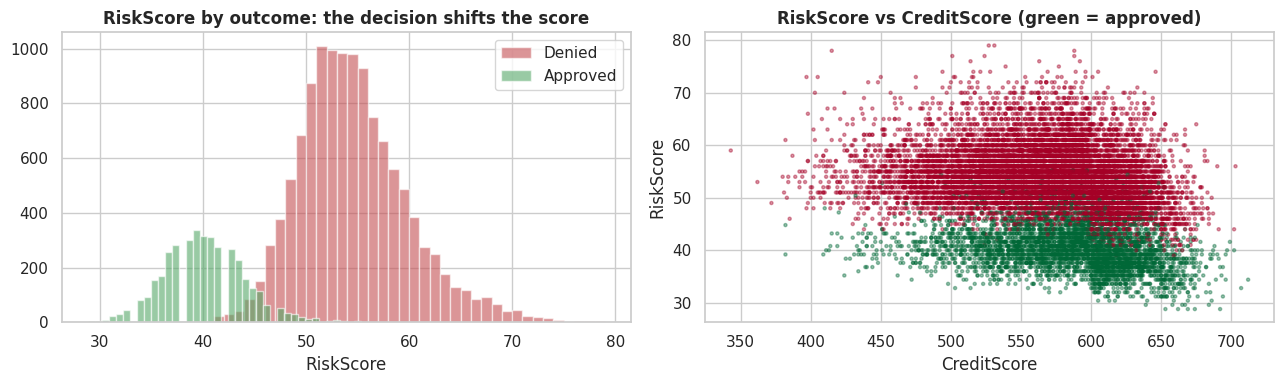

In [22]:
# ---------- RiskScore: why it cannot be a feature for the classification model ----------
print('corr(RiskScore, LoanApproved) =', round(eda['RiskScore'].corr(eda[TARGET]), 3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for v, col, lab in [(0, '#c44e52', 'Denied'), (1, '#55a868', 'Approved')]:
    ax[0].hist(eda.loc[eda[TARGET] == v, 'RiskScore'], bins=40, alpha=.6, color=col, label=lab)
ax[0].set_title('RiskScore by outcome: the decision shifts the score'); ax[0].legend(); ax[0].set_xlabel('RiskScore')
ax[1].scatter(eda['CreditScore'], eda['RiskScore'], c=eda[TARGET], cmap='RdYlGn', s=5, alpha=.4); ax[1].set_xlabel('CreditScore'); ax[1].set_ylabel('RiskScore'); ax[1].set_title('RiskScore vs CreditScore (green = approved)')
plt.tight_layout()
print(eda.groupby(TARGET)['RiskScore'].describe().round(2))


`RiskScore` is correlated at −0.77 with approval, and its distribution is shifted by about 14 points between approved (mean 40) and denied (mean 54) applicants. A score computed from the applicant's file would not shift that cleanly with the *decision itself*, so it appears to be calculated using the outcome (the dataset's own generator script confirms it multiplies the score by 0.8 for approved loans). **It would not exist at the time a real decision is made**, so using it as a feature would be leakage. It is excluded from the classification model and used only as the regression target in the framing comparison.

### 4d. Feature-engineering opportunities identified
`LoanToIncome` (loan size vs. annual income), `AssetsToLiabilities`, `IncomePerDependent`, and `InterestSpread` (rate charged minus base rate), plus "was missing" flags for fields with gaps. These are built inside the pipeline in the next section.


## Data Preparation
5. Design your preprocessing strategy:
- Create separate preprocessing flows for different feature types
- Must utilize ColumnTransformer and Pipeline
- Consider using FeatureUnion as well
- Handle missing values appropriately for each feature
- Handle Categorical and Ordinal data appropriately
- Scale numeric values if model requires it (linear model)
- Document your reasoning for each preprocessing decision

### Preprocessing design

Everything below lives **inside one scikit-learn `Pipeline`**, so each cross-validation fold learns its own medians, clipping bounds, scaling and encodings from its own training rows (no leakage).

| Step | Features | What it does and why |
|---|---|---|
| `FeatureEngineer` (*custom transformer*) | all | Adds `LoanToIncome`, `AssetsToLiabilities`, `IncomePerDependent`, `InterestSpread`: ratios lenders actually use, and cheap for linear models to benefit from. |
| **Skewed money / ratio flow** (`ColumnTransformer` branch) | income, loan amount, balances, assets, liabilities, net worth, payments, total DTI and the new ratios | `log1p` (fixes skew of 5–6) → impute (median) → `Winsorizer` (*custom transformer*, 1 %/99 % bounds learned on training data) → `StandardScaler` *(linear / distance models only)*. A **`FeatureUnion`** adds a `MissingIndicator` so that "was missing" (savings) becomes a feature. |
| **Other numeric flow** | age, credit score, counts, rates … | median impute (safety net for future data) → winsorise → scale *(linear / distance models only)*. |
| **Ordinal flow** | `EducationLevel` | most-frequent impute → ordered integer code (High School=0 … Doctorate=4); a **`FeatureUnion`** adds a missing flag, because education is *informatively* missing. |
| **Nominal flow** | employment, marital status, home ownership, loan purpose | missing → explicit `'Unknown'` level → one-hot encoding (`handle_unknown='ignore'`). |
| **Binary flow** | bankruptcy, previous defaults | passed through as 0/1. |
| Dropped | `AnnualIncome`, `RiskScore` | corrupted/duplicate and leaking respectively (see EDA). |

Scaling is applied only for logistic regression and KNN; tree-based models are scale-invariant, so `scale=False` is used for them. Feature selection (an L1-based or tree-based `SelectFromModel`) is a pipeline step that is switched on or off during tuning.


In [23]:
# ---------- Custom transformers ----------
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Adds domain ratios that lenders actually use. Purely row-wise (nothing is learned), so it is leak-free."""
    def fit(self, X, y=None):
        self.columns_out_ = list(self.transform(X.iloc[:5]).columns)
        return self
    def transform(self, X):
        X = X.copy()
        X['LoanToIncome'] = X['LoanAmount'] / (12 * X['MonthlyIncome'])                 # loan size relative to annual income
        X['AssetsToLiabilities'] = X['TotalAssets'] / X['TotalLiabilities']             # balance-sheet strength
        X['IncomePerDependent'] = X['MonthlyIncome'] / (1 + X['NumberOfDependents'])    # disposable-income proxy
        X['InterestSpread'] = X['InterestRate'] - X['BaseInterestRate']                 # pricing premium on top of the base rate
        return X
    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_out_, dtype=object)

class Winsorizer(BaseEstimator, TransformerMixin):
    """Learns the lower/upper quantiles on the TRAINING fold and clips to them (tames outliers for linear models)."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower; self.upper = upper
    def fit(self, X, y=None):
        A = np.asarray(X, dtype=float)
        self.lo_ = np.nanquantile(A, self.lower, axis=0); self.hi_ = np.nanquantile(A, self.upper, axis=0)
        self.n_features_in_ = A.shape[1]
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


In [24]:
# ---------- Feature groups used by the pipeline ----------
# AnnualIncome is NOT used: it is a text field, 1 % of values are inflated (EDA), and it duplicates MonthlyIncome (r = 0.99).
# RiskScore is NOT used: it is computed with knowledge of the decision (EDA) -> target leakage.
SKEWED_COLS  = ['MonthlyIncome', 'LoanAmount', 'MonthlyDebtPayments', 'SavingsAccountBalance', 'CheckingAccountBalance',
                'TotalAssets', 'TotalLiabilities', 'NetWorth', 'MonthlyLoanPayment',
                'TotalDebtToIncomeRatio', 'LoanToIncome', 'AssetsToLiabilities', 'IncomePerDependent']   # log1p-transformed
NUMERIC_COLS = ['Age', 'CreditScore', 'Experience', 'LoanDuration', 'NumberOfDependents', 'CreditCardUtilizationRate',
                'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'PaymentHistory',
                'LengthOfCreditHistory', 'UtilityBillsPaymentHistory', 'JobTenure', 'BaseInterestRate', 'InterestRate', 'InterestSpread']
BINARY_COLS  = ['BankruptcyHistory', 'PreviousLoanDefaults']
ORDINAL_COL  = ['EducationLevel']
EDU_ORDER    = ['High School', 'Associate', 'Bachelor', 'Master', 'Doctorate']
NOMINAL_COLS = ['EmploymentStatus', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose']


In [25]:
def make_imputer(kind='median'):
    return {'median': SimpleImputer(strategy='median'), 'mean': SimpleImputer(strategy='mean'),
            'knn': KNNImputer(n_neighbors=5), 'iterative': IterativeImputer(random_state=RANDOM_STATE, max_iter=10)}[kind]

def build_preprocessor(scale=True, exclude=(), imputer='median'):
    """Separate flows per feature type, combined with a ColumnTransformer.
       scale=True  -> for distance / linear models;  scale=False -> tree models (scale-invariant)."""
    keep = lambda cols: [c for c in cols if c not in exclude]

    # (a) skewed money & ratio features: log1p -> impute -> winsorise -> (scale); FeatureUnion adds "was missing" flags
    skew_steps = [('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('impute', make_imputer(imputer)), ('winsor', Winsorizer())]
    if scale: skew_steps.append(('scale', StandardScaler()))
    skewed = FeatureUnion([('values', Pipeline(skew_steps)), ('missing_flag', MissingIndicator(features='missing-only', error_on_new=False))])

    # (b) other numeric features: median impute (safety net) -> winsorise -> (scale)
    num_steps = [('impute', SimpleImputer(strategy='median')), ('winsor', Winsorizer())]
    if scale: num_steps.append(('scale', StandardScaler()))
    numeric = Pipeline(num_steps)

    # (c) ordinal education: most-frequent impute -> ordered integer code; FeatureUnion adds an "education missing" flag
    ord_steps = [('impute', SimpleImputer(strategy='most_frequent')),
                 ('ordinal', OrdinalEncoder(categories=[EDU_ORDER], handle_unknown='use_encoded_value', unknown_value=-1))]
    if scale: ord_steps.append(('scale', StandardScaler()))
    ordinal = FeatureUnion([('level', Pipeline(ord_steps)), ('missing_flag', MissingIndicator(features='missing-only', error_on_new=False))])

    # (d) nominal categories: explicit 'Unknown' level for missing -> one-hot
    nominal = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Unknown')),
                        ('onehot', OneHotEncoder(handle_unknown='ignore'))])

    transformers = [('skewed', skewed, keep(SKEWED_COLS)), ('numeric', numeric, keep(NUMERIC_COLS)),
                    ('ordinal', ordinal, keep(ORDINAL_COL)), ('nominal', nominal, keep(NOMINAL_COLS)),
                    ('binary', 'passthrough', keep(BINARY_COLS))]
    transformers = [t for t in transformers if len(t[2]) > 0]
    return ColumnTransformer(transformers, remainder='drop', sparse_threshold=0)   # always dense output

def make_pipeline(model, scale=True, select=None, exclude=(), imputer='median'):
    """Complete pipeline: feature engineering -> preprocessing -> (optional feature selection) -> model."""
    return Pipeline([('fe', FeatureEngineer()), ('prep', build_preprocessor(scale, exclude, imputer)),
                     ('select', select if select is not None else 'passthrough'), ('model', model)])


In [26]:
# ---------- Demonstrate the preprocessing on the training data ----------
demo = Pipeline(make_pipeline(LogisticRegression()).steps[:2])
Xt = demo.fit_transform(X_train)
names = demo.get_feature_names_out()
print(f'Input: {X_train.shape[1]} raw columns  ->  output: {Xt.shape[1]} model features')
print('NaNs remaining after preprocessing:', int(np.isnan(Xt).sum()))
Xt_df = pd.DataFrame(Xt, columns=names)
print('\nExample of the processed (scaled) features - mean ~0, std ~1 for continuous ones:')
display(Xt_df.iloc[:, :6].describe().loc[['mean', 'std', 'min', 'max']].round(2))
print('Feature names by branch:'); print(pd.Series([n.split('__')[0] for n in names]).value_counts().to_string())
print('\nEngineered features added:', [c for c in demo.named_steps['fe'].columns_out_ if c not in X_train.columns])
print('Missing-flag features created:', [n for n in names if 'missing_flag' in n])
# Applying the FITTED pipeline to the test set (no re-fitting -> no leakage)
print('Test set transforms to shape', demo.transform(X_test).shape)


Input: 33 raw columns  ->  output: 51 model features
NaNs remaining after preprocessing: 0

Example of the processed (scaled) features - mean ~0, std ~1 for continuous ones:


,skewed__values__MonthlyIncome,skewed__values__LoanAmount,skewed__values__MonthlyDebtPayments,skewed__values__SavingsAccountBalance,skewed__values__CheckingAccountBalance,skewed__values__TotalAssets
mean,-0.00,0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.96,-2.38,-2.39,-2.43,-2.38,-2.24
max,2.40,2.36,2.35,2.42,2.38,2.35


Feature names by branch:
nominal    17
numeric    16
skewed     14
ordinal     2
binary      2

Engineered features added: ['LoanToIncome', 'AssetsToLiabilities', 'IncomePerDependent', 'InterestSpread']
Missing-flag features created: ['skewed__missing_flag__missingindicator_SavingsAccountBalance', 'ordinal__missing_flag__missingindicator_EducationLevel']
Test set transforms to shape (4000, 51)


The 33 usable raw columns become **51 model-ready features**. No NaNs remain, the continuous features have mean 0 and standard deviation 1 (in the scaled variant), two missing-value flags were created (`SavingsAccountBalance`, `EducationLevel`), and the fitted pipeline transforms the test set without re-fitting.

## Modeling
6. Implement your modeling approach:
- Choose appropriate model algorithms based on your problem definition
- Set up validation strategy with chosen metrics
- Use a train test split and cross validation
- Create complete pipeline including any preprocessing and model
- Document your reasoning for each modeling decision

7. Optimize your model:
- Define parameter grid based on your understanding of the algorithms
- Implement GridSearchCV and/or RandomizedSearchCV with chosen metrics
- Consider tuning preprocessing steps
- Track and document the impact of different parameter combinations
- Consider the trade-offs between different model configurations

NOTE: Be mindful of time considerations - showcase “how to tune” 

### 6a. Validation strategy
- **Train/test split:** 80/20, stratified (done above). The test set is used once, at the end.
- **Cross-validation:** 5-fold *stratified* CV on the training set, so every fold keeps the 24 % approval rate. All reported model-selection numbers are CV results.
- **Metrics:** ROC-AUC, PR-AUC, precision, recall and F1 at the default 0.5 cut-off, plus the **custom business cost** at (i) 0.5, (ii) the theoretical break-even 0.862 and (iii) the best threshold found on the out-of-fold predictions. The *train* AUC is also recorded to spot over-fitting.
- **Why probabilities and thresholds:** every model outputs P(approve); the threshold is a business decision, so it is optimised separately for each model rather than fixed at 0.5.

### 6b. Candidate algorithms and why
| Model | Reason for inclusion |
|---|---|
| Baseline (class prior) | The floor: any real model must beat 0.5 AUC. |
| Logistic Regression | Transparent, regulator-friendly, well-calibrated probabilities; needs scaled inputs. |
| Decision Tree (depth 6) | Fully readable rules; shows what a simple, interpretable tree can do. |
| K-Nearest Neighbors | Distance-based contrast; sensitive to scaling and the many irrelevant features here. |
| Random Forest | Bagged trees: robust to outliers and non-linearity. |
| Gradient Boosting & Hist Gradient Boosting | Usually the strongest on tabular data; the histogram version is much faster. |
| Soft-voting ensemble (LR + RF + HGB) | Blends a linear, a bagging and a boosting model. |


In [27]:
# ---------- Validation strategy ----------
# 5-fold stratified CV on the TRAINING set (the 20 % test set stays untouched until the final evaluation).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
THRESHOLDS = np.round(np.arange(0.05, 0.9951, 0.005), 3)

def cost_curve(y_true, p, thresholds=THRESHOLDS):
    """Cost per applicant ($) for every decision threshold."""
    y_true = np.asarray(y_true); p = np.asarray(p); out = []
    for t in thresholds:
        pred = p >= t
        out.append((COST_FP * ((y_true == 0) & pred).sum() + COST_FN * ((y_true == 1) & ~pred).sum()) / len(y_true))
    return np.array(out)

def best_threshold(y_true, p):
    c = cost_curve(y_true, p); i = int(c.argmin())
    return THRESHOLDS[i], c[i]

def cv_evaluate(pipe, X, y, cv=cv):
    """Fits the pipeline once per fold; returns out-of-fold probabilities and a per-fold metric table."""
    oof = np.zeros(len(y)); rows = []; t0 = time.time()
    for tr, va in cv.split(X, y):
        m = clone(pipe).fit(X.iloc[tr], y.iloc[tr])
        p_va = m.predict_proba(X.iloc[va])[:, 1]; p_tr = m.predict_proba(X.iloc[tr])[:, 1]
        oof[va] = p_va; yv = y.iloc[va]
        d05 = (p_va >= .5).astype(int); dB = (p_va >= BAYES_T).astype(int)
        rows.append({'roc_auc': roc_auc_score(yv, p_va), 'pr_auc': average_precision_score(yv, p_va),
                     'train_roc_auc': roc_auc_score(y.iloc[tr], p_tr),
                     'precision@0.5': precision_score(yv, d05, zero_division=0), 'recall@0.5': recall_score(yv, d05),
                     'f1@0.5': f1_score(yv, d05, zero_division=0),
                     'cost@0.5': business_cost(yv, d05) / len(yv), f'cost@{BAYES_T:.3f}': business_cost(yv, dB) / len(yv)})
    f = pd.DataFrame(rows); f['fit_seconds'] = (time.time() - t0) / len(f)
    return oof, f

def summarize(name, oof, folds, y):
    t_best, c_best = best_threshold(y, oof)
    s = folds.mean()
    return {'Model': name, 'ROC-AUC': s['roc_auc'], 'ROC-AUC std': folds['roc_auc'].std(), 'PR-AUC': s['pr_auc'],
            'Train ROC-AUC': s['train_roc_auc'], 'Precision@0.5': s['precision@0.5'], 'Recall@0.5': s['recall@0.5'], 'F1@0.5': s['f1@0.5'],
            'Cost/appl @0.5 ($)': s['cost@0.5'], f'Cost/appl @{BAYES_T:.3f} ($)': s[f'cost@{BAYES_T:.3f}'],
            'Best OOF threshold': t_best, 'Cost/appl @best ($)': c_best, 'Fit s/fold': s['fit_seconds']}


In [28]:
# ---------- Candidate algorithms ----------
# (name, estimator, needs_scaling).  Linear / distance models get scaled features; tree models do not need scaling.
zoo = {
    'Baseline (class prior)':      (DummyClassifier(strategy='prior'), False),
    'Logistic Regression':         (LogisticRegression(max_iter=3000, C=1.0), True),
    'Decision Tree':               (DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE), False),
    'K-Nearest Neighbors':         (KNeighborsClassifier(n_neighbors=25, weights='distance'), True),
    'Random Forest':               (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE), False),
    'Gradient Boosting':           (GradientBoostingClassifier(n_estimators=150, max_depth=3, random_state=RANDOM_STATE), False),
    'Hist Gradient Boosting':      (HistGradientBoostingClassifier(random_state=RANDOM_STATE), False),
}
# Soft-voting ENSEMBLE of three very different learners (linear + bagging + boosting)
zoo['Voting Ensemble (LR+RF+HGB)'] = (VotingClassifier([
    ('lr', LogisticRegression(max_iter=3000)),
    ('rf', RandomForestClassifier(n_estimators=150, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)),
    ('hgb', HistGradientBoostingClassifier(random_state=RANDOM_STATE))], voting='soft'), True)

results, oof_store = [], {}
for name, (est, scale) in zoo.items():
    oof, folds = cv_evaluate(make_pipeline(est, scale=scale), X_train, y_train)
    oof_store[name] = oof; results.append(summarize(name, oof, folds, y_train))
    print(f'done: {name:30s} ROC-AUC={folds["roc_auc"].mean():.4f}  ({folds["fit_seconds"].mean():.1f}s/fold)')
comparison = pd.DataFrame(results).set_index('Model')
comparison.round(4)


done: Baseline (class prior)         ROC-AUC=0.5000  (0.1s/fold)
done: Logistic Regression            ROC-AUC=0.9884  (0.2s/fold)
done: Decision Tree                  ROC-AUC=0.9491  (0.3s/fold)
done: K-Nearest Neighbors            ROC-AUC=0.9652  (1.4s/fold)
done: Random Forest                  ROC-AUC=0.9776  (6.5s/fold)
done: Gradient Boosting              ROC-AUC=0.9901  (14.6s/fold)
done: Hist Gradient Boosting         ROC-AUC=0.9907  (1.1s/fold)
done: Voting Ensemble (LR+RF+HGB)    ROC-AUC=0.9915  (6.0s/fold)


,ROC-AUC,ROC-AUC std,PR-AUC,Train ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5,Cost/appl @0.5 ($),Cost/appl @0.862 ($),Best OOF threshold,Cost/appl @best ($),Fit s/fold
Model,,,,,,,,,,,,
Baseline (class prior),0.5000,0.0000,0.2390,0.5000,0.0000,0.0000,0.0000,1912.000,1912.000,0.240,1912.000,0.1392
Logistic Regression,0.9884,0.0013,0.9700,0.9891,0.9067,0.8930,0.8997,1304.500,688.500,0.820,684.500,0.2483
Decision Tree,0.9491,0.0077,0.8497,0.9649,0.8110,0.7458,0.7766,2567.250,1561.000,0.935,1501.875,0.3328
K-Nearest Neighbors,0.9652,0.0030,0.9026,1.0000,0.9114,0.6407,0.7523,1430.750,1775.125,0.565,1238.000,1.3870
Random Forest,0.9776,0.0039,0.9362,0.9986,0.8763,0.8049,0.8390,1732.375,1314.000,0.700,1008.875,6.4720
Gradient Boosting,0.9901,0.0024,0.9718,0.9964,0.9157,0.8800,0.8974,1198.250,768.875,0.760,670.375,14.5578
Hist Gradient Boosting,0.9907,0.0020,0.9729,0.9995,0.9129,0.8904,0.9015,1225.125,687.000,0.840,667.875,1.1074
Voting Ensemble (LR+RF+HGB),0.9915,0.0018,0.9753,0.9993,0.9231,0.8881,0.9052,1098.375,848.875,0.720,629.875,5.9541


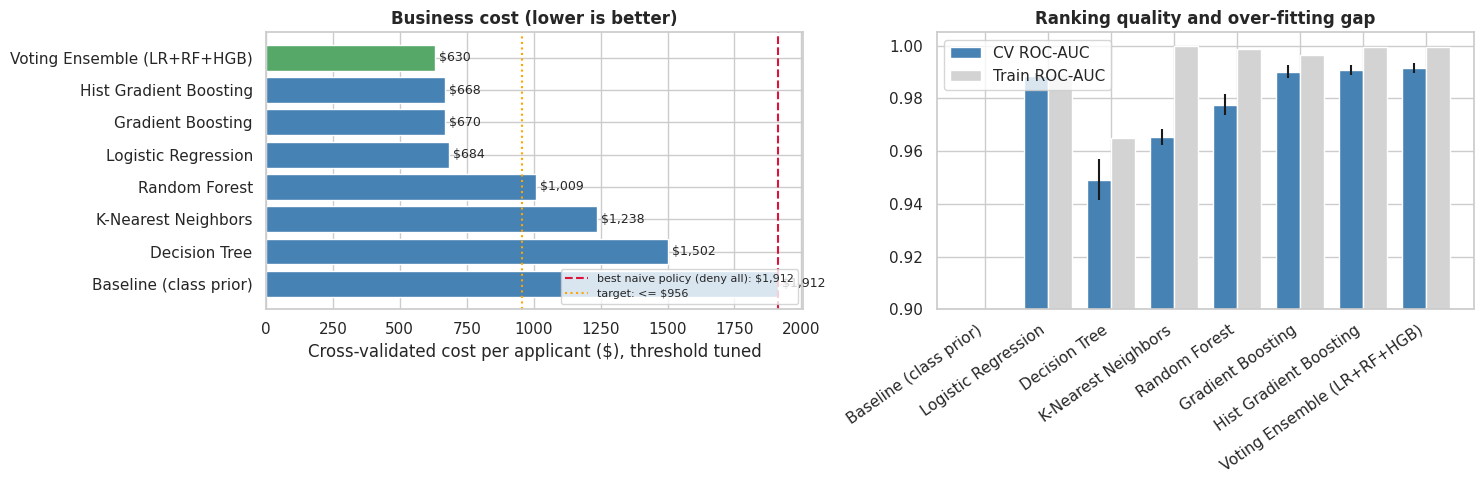

In [29]:
# ---------- Compare the candidate models ----------
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
order = comparison.sort_values('Cost/appl @best ($)').index
ax[0].barh(order, comparison.loc[order, 'Cost/appl @best ($)'], color=['#55a868' if i == order[0] else 'steelblue' for i in order])
ax[0].axvline(best_naive_cost, color='crimson', ls='--', label=f'best naive policy (deny all): ${best_naive_cost:,.0f}')
ax[0].axvline(0.5 * best_naive_cost, color='orange', ls=':', label=f'target: <= ${0.5 * best_naive_cost:,.0f}')
for i, v in enumerate(comparison.loc[order, 'Cost/appl @best ($)']): ax[0].text(v, i, f' ${v:,.0f}', va='center', fontsize=9)
ax[0].invert_yaxis(); ax[0].set_xlabel('Cross-validated cost per applicant ($), threshold tuned'); ax[0].set_title('Business cost (lower is better)'); ax[0].legend(fontsize=8, loc='lower right')
x = np.arange(len(comparison)); w = .38
ax[1].bar(x - w/2, comparison['ROC-AUC'], w, label='CV ROC-AUC', yerr=comparison['ROC-AUC std'], color='steelblue')
ax[1].bar(x + w/2, comparison['Train ROC-AUC'], w, label='Train ROC-AUC', color='lightgray')
ax[1].set_xticks(x); ax[1].set_xticklabels(comparison.index, rotation=35, ha='right'); ax[1].set_ylim(.9, 1.005); ax[1].set_title('Ranking quality and over-fitting gap'); ax[1].legend()
plt.tight_layout()


**Results (5-fold CV on the training set).**

| Model | ROC-AUC | Train AUC | Cost/applicant at best threshold |
|---|---|---|---|
| Baseline | 0.500 | 0.500 | $1,912 |
| Logistic Regression | 0.988 | 0.989 | $685 |
| Decision Tree | 0.949 | 0.965 | $1,502 |
| K-Nearest Neighbors | 0.965 | 1.000 | $1,238 |
| Random Forest | 0.978 | 0.999 | $1,009 |
| Gradient Boosting | 0.990 | 0.996 | $670 |
| Hist Gradient Boosting | 0.991 | 0.9995 | $668 |
| Voting ensemble | 0.992 | 0.999 | $630 |

- **Boosting, logistic regression and the ensemble form a clear top group** (AUC ≥ 0.988); the single tree, KNN and the random forest are behind. KNN memorises the training data (train AUC 1.000) but generalises worse because most of its 51 dimensions are noise.
- **Complexity vs. performance:** the *linear* model is within about $17 per applicant of the best boosted model, which is remarkable and matters for interpretability: much of the signal is close to linear in log-income, DTI and the interest rate.
- **The threshold is worth as much as the algorithm.** Logistic regression costs **$1,305** per applicant at 0.5, **$689** at the break-even 0.862 and **$685** at its tuned threshold. Every top model reaches all four success targets already, so tuning is about squeezing out the remaining dollars.

### 7a. Tuning a preprocessing choice: imputation strategy
Only `SavingsAccountBalance` has a numeric gap (2.9 %), so I expect little difference. I tested it rather than assumed it (logistic regression as the probe model), and also ablated the missing-value flags.


In [30]:
# ---------- Tuning a PREPROCESSING step: imputation strategy (Logistic Regression as the probe model) ----------
# Only SavingsAccountBalance (2.9 %) is a numeric gap, so we expect small differences - the point is to verify, not assume.
imp_rows = []
for kind in ['median', 'mean', 'knn', 'iterative']:
    oof, f = cv_evaluate(make_pipeline(LogisticRegression(max_iter=3000), scale=True, imputer=kind), X_train, y_train)
    imp_rows.append({**summarize(f'impute = {kind}', oof, f, y_train)})
# Ablation: what do the "was missing" flags buy us?
noflag = make_pipeline(LogisticRegression(max_iter=3000), scale=True).set_params(prep__ordinal__missing_flag='drop', prep__skewed__missing_flag='drop')
oof, f = cv_evaluate(noflag, X_train, y_train); imp_rows.append({**summarize('median, NO missing-flags', oof, f, y_train)})
imp_df = pd.DataFrame(imp_rows).set_index('Model')[['ROC-AUC', 'PR-AUC', 'Cost/appl @best ($)', 'Fit s/fold']]
imp_df.round(4)


,ROC-AUC,PR-AUC,Cost/appl @best ($),Fit s/fold
Model,,,,
impute = median,0.9884,0.970,684.500,0.2880
impute = mean,0.9884,0.970,680.625,0.2597
impute = knn,0.9884,0.970,682.875,1.0700
impute = iterative,0.9884,0.970,685.750,0.4192
"median, NO missing-flags",0.9876,0.968,696.250,0.2454


Median, mean, KNN and iterative imputation are **statistically indistinguishable** (AUC 0.9884 for all, cost within $5 of each other), so the cheapest and most robust option, **median imputation**, is kept. The "was missing" flags are worth keeping: removing them raises cost by about $12 per applicant and lowers AUC (0.9876 vs. 0.9884), driven by the informative `EducationLevel` gaps.

### 7b. Tuning method: what is tuned and how
- **Tuning objective:** the *business cost at the best threshold* (a custom scorer), tracked together with ROC-AUC, PR-AUC and cost at the break-even threshold (multi-metric `scoring`, `refit` on cost). Using the best threshold *per fold* keeps the comparison fair for settings such as `class_weight` that shift probabilities.
- **Efficiency:** logistic regression is cheap, so it gets an exhaustive `GridSearchCV`. Boosting has many more knobs, so it uses a **two-stage search**: a broad `RandomizedSearchCV` first, then a narrow `GridSearchCV` around the winner. All searches use the same 5 stratified folds and the training data only.
- **Preprocessing and model parameters are tuned together** (winsorising bounds and feature selection are part of the search space).

#### Model 1: Logistic Regression (80 configurations × 5 folds)


In [31]:
# ---------- Tuning scorers (multi-metric) ----------
def best_cost_scorer(estimator, X, y):
    """Negative cost per applicant at the best threshold for this fold. Using the best threshold (not a fixed one)
    keeps the comparison fair for settings such as class_weight that shift the probabilities."""
    p = estimator.predict_proba(X)[:, 1]; y = np.asarray(y)
    pred = p[:, None] >= THRESHOLDS[None, :]
    fp = ((y == 0)[:, None] & pred).sum(0); fn = ((y == 1)[:, None] & ~pred).sum(0)
    return -float((COST_FP * fp + COST_FN * fn).min()) / len(y)

SCORING = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision',
           'neg_cost_bayes': cost_scorer, 'neg_cost_best': best_cost_scorer}


In [32]:
# ---------- Model 1: Logistic Regression - exhaustive GridSearchCV over model AND preprocessing / selection ----------
t0 = time.time()
lr_pipe = make_pipeline(LogisticRegression(solver='liblinear', max_iter=2000), scale=True)
lr_grid = {
    'model__C': [0.03, 0.1, 0.3, 1, 3],                                  # regularisation strength (inverse)
    'model__penalty': ['l1', 'l2'],                                      # sparse vs. smooth coefficients
    'model__class_weight': [None, 'balanced'],                           # imbalance handling
    'prep__skewed__values__winsor': [Winsorizer(0.0, 1.0), Winsorizer(0.01, 0.99)],   # PREPROCESSING: no clipping vs. 1 %/99 % clipping
    'select': ['passthrough',                                            # FEATURE SELECTION inside the pipeline
               SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear', C=0.05), threshold=1e-5)],
}
gs_lr = GridSearchCV(lr_pipe, lr_grid, scoring=SCORING, refit='neg_cost_best', cv=cv, n_jobs=-1)
gs_lr.fit(X_train, y_train)
print(f'GridSearchCV (LR): {len(gs_lr.cv_results_["params"])} configurations x 5 folds in {time.time() - t0:.0f}s')
print('Best params:', {k: (v if not hasattr(v, 'get_params') else type(v).__name__ + str({p: q for p, q in v.get_params().items() if p in ('lower', 'upper', 'C')}))
                       for k, v in gs_lr.best_params_.items()})
print(f'Best CV cost per applicant (best threshold): ${-gs_lr.best_score_:,.1f}')


GridSearchCV (LR): 80 configurations x 5 folds in 286s
Best params: {'model__C': 0.3, 'model__class_weight': None, 'model__penalty': 'l2', 'prep__skewed__values__winsor': "Winsorizer{'lower': 0.01, 'upper': 0.99}", 'select': 'passthrough'}
Best CV cost per applicant (best threshold): $654.6


In [33]:
def tidy(cv_results, keep_params):
    r = pd.DataFrame(cv_results)
    out = pd.DataFrame({'cost/applicant ($)': -r['mean_test_neg_cost_best'], 'cost std': r['std_test_neg_cost_best'],
                        'cost @0.862 ($)': -r['mean_test_neg_cost_bayes'], 'ROC-AUC': r['mean_test_roc_auc'], 'PR-AUC': r['mean_test_pr_auc'], 'fit s': r['mean_fit_time']})
    for p in keep_params:
        col = r[f'param_{p}'].astype(object); col = col.where(col.notna(), 'none'); out[p.split('__')[-1] if p != 'select' else 'select'] = col.map(lambda v: type(v).__name__ if hasattr(v, 'get_params') and not isinstance(v, Winsorizer)
                                                                  else (f'clip {v.lower:g}-{v.upper:g}' if isinstance(v, Winsorizer) else ('none' if v is None else v)))
    return out
lr_res = tidy(gs_lr.cv_results_, ['model__C', 'model__penalty', 'model__class_weight', 'prep__skewed__values__winsor', 'select'])
print('Top 8 configurations:'); display(lr_res.sort_values('cost/applicant ($)').head(8).round(4))
print('\nAverage impact of each setting (mean cost/applicant across all configs that use it):')
for col in ['C', 'penalty', 'class_weight', 'winsor', 'select']:
    print(lr_res.groupby(col)['cost/applicant ($)'].mean().round(1).to_dict())


Top 8 configurations:


,cost/applicant ($),cost std,cost @0.862 ($),ROC-AUC,PR-AUC,fit s,C,penalty,class_weight,winsor,select
38,654.625,38.9282,712.500,0.9882,0.9696,0.2621,0.3,l2,none,clip 0.01-0.99,passthrough
52,654.750,41.9460,700.875,0.9887,0.9705,0.2848,1.0,l2,none,clip 0-1,passthrough
35,655.125,44.9399,695.875,0.9885,0.9701,0.6844,0.3,l1,none,clip 0.01-0.99,SelectFromModel
51,657.250,41.6319,694.625,0.9886,0.9702,0.6449,1.0,l1,none,clip 0.01-0.99,SelectFromModel
18,657.875,39.4525,727.625,0.9881,0.9695,0.4919,0.1,l1,none,clip 0.01-0.99,passthrough
16,658.875,43.8951,720.000,0.9885,0.9700,0.5201,0.1,l1,none,clip 0-1,passthrough
19,659.000,39.1643,723.000,0.9881,0.9695,0.7087,0.1,l1,none,clip 0.01-0.99,SelectFromModel
17,659.250,43.5144,719.000,0.9885,0.9700,0.6934,0.1,l1,none,clip 0-1,SelectFromModel



Average impact of each setting (mean cost/applicant across all configs that use it):
{0.03: 711.2, 0.1: 672.5, 0.3: 672.1, 1.0: 674.7, 3.0: 675.4}
{'l1': 679.9, 'l2': 682.4}
{'balanced': 690.1, 'none': 672.2}
{'clip 0-1': 681.8, 'clip 0.01-0.99': 680.5}
{'SelectFromModel': 682.1, 'passthrough': 680.2}


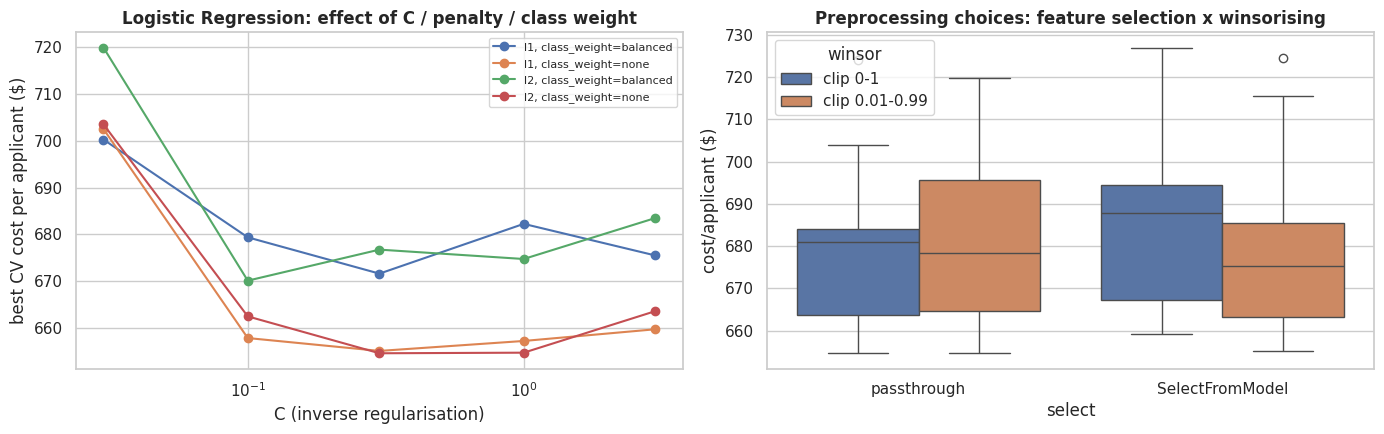

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for (pen, cw), g in lr_res.groupby(['penalty', 'class_weight'], dropna=False):
    gg = g.groupby('C')['cost/applicant ($)'].min()
    ax[0].plot(gg.index, gg.values, marker='o', label=f'{pen}, class_weight={cw}')
ax[0].set_xscale('log'); ax[0].set_xlabel('C (inverse regularisation)'); ax[0].set_ylabel('best CV cost per applicant ($)'); ax[0].set_title('Logistic Regression: effect of C / penalty / class weight'); ax[0].legend(fontsize=8)
sns.boxplot(data=lr_res, x='select', y='cost/applicant ($)', hue='winsor', ax=ax[1]); ax[1].set_title('Preprocessing choices: feature selection x winsorising')
plt.tight_layout()


**What the grid shows.** Regularisation matters only at the extreme: a very strong penalty (C = 0.03) under-fits (mean cost ≈ $711), while C between 0.1 and 3 is flat (≈ $672 to $675). L1 and L2 behave almost identically; `class_weight='balanced'` is *slightly worse* on average (≈ $690 vs. ≈ $672 without it), which is unsurprising since the threshold already handles imbalance; winsorising and L1-based feature selection make almost no difference. The best configuration is **C = 0.3, L2, no class weights, 1 %/99 % clipping, no feature selection** at **$655** per applicant (per-fold best threshold). The top eight configurations are all within $5 of each other, so this model is robust to its settings; but it has plateaued, which points to a *non-linear* effect that a linear model cannot capture.

#### Model 2: Hist Gradient Boosting (two-stage search)


In [35]:
# ---------- Model 2: Hist Gradient Boosting - STAGE 1: broad RandomizedSearchCV ----------
from scipy.stats import loguniform
t0 = time.time()
hgb_pipe = make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False)
hgb_dist = {
    'model__learning_rate': loguniform(0.02, 0.3),
    'model__max_iter': [100, 200, 300],
    'model__max_leaf_nodes': [8, 15, 31, 63],
    'model__min_samples_leaf': [10, 20, 50, 100],
    'model__l2_regularization': [0.0, 0.1, 1.0, 10.0],
    'select': ['passthrough', SelectFromModel(ExtraTreesClassifier(n_estimators=100, max_depth=8, n_jobs=-1, random_state=RANDOM_STATE), threshold='0.5*mean')],
}
rs_hgb = RandomizedSearchCV(hgb_pipe, hgb_dist, n_iter=20, scoring=SCORING, refit='neg_cost_best', cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
rs_hgb.fit(X_train, y_train)
print(f'RandomizedSearchCV (HGB, stage 1): 20 configurations x 5 folds in {time.time() - t0:.0f}s')
bp = rs_hgb.best_params_
print('Best stage-1 params:', {k: (round(v, 4) if isinstance(v, float) else (type(v).__name__ if hasattr(v, 'get_params') else v)) for k, v in bp.items()})
print(f'Best CV cost per applicant: ${-rs_hgb.best_score_:,.1f}')


RandomizedSearchCV (HGB, stage 1): 20 configurations x 5 folds in 149s
Best stage-1 params: {'model__l2_regularization': 1.0, 'model__learning_rate': np.float64(0.2053), 'model__max_iter': 300, 'model__max_leaf_nodes': 8, 'model__min_samples_leaf': 10, 'select': 'passthrough'}
Best CV cost per applicant: $568.5


In [36]:
# ---------- STAGE 2: narrow GridSearchCV around the stage-1 winner ----------
t0 = time.time()
lr0, leaf0, it0 = bp['model__learning_rate'], bp['model__max_leaf_nodes'], bp['model__max_iter']
grid2 = {
    'model__learning_rate': [round(lr0 * f, 4) for f in (0.6, 1.0, 1.5)],
    'model__max_leaf_nodes': sorted({max(4, leaf0 // 2), leaf0, leaf0 * 2}),
    'model__max_iter': sorted({it0, int(it0 * 1.5)}),
    'model__min_samples_leaf': [bp['model__min_samples_leaf']],
    'model__l2_regularization': [bp['model__l2_regularization']],
    'select': [bp['select']],
}
gs_hgb = GridSearchCV(hgb_pipe, grid2, scoring=SCORING, refit='neg_cost_best', cv=cv, n_jobs=-1)
gs_hgb.fit(X_train, y_train)
print(f'GridSearchCV (HGB, stage 2): {len(gs_hgb.cv_results_["params"])} configurations x 5 folds in {time.time() - t0:.0f}s')
print('Stage-2 grid:', {k: v for k, v in grid2.items() if k != 'select'})
print('Best stage-2 params:', {k: (round(v, 4) if isinstance(v, float) else (type(v).__name__ if hasattr(v, 'get_params') else v)) for k, v in gs_hgb.best_params_.items()})
print(f'Best CV cost per applicant: ${-gs_hgb.best_score_:,.1f}   (stage 1 was ${-rs_hgb.best_score_:,.1f})')


GridSearchCV (HGB, stage 2): 18 configurations x 5 folds in 94s
Stage-2 grid: {'model__learning_rate': [np.float64(0.1232), np.float64(0.2053), np.float64(0.308)], 'model__max_leaf_nodes': [4, 8, 16], 'model__max_iter': [300, 450], 'model__min_samples_leaf': [10], 'model__l2_regularization': [1.0]}
Best stage-2 params: {'model__l2_regularization': 1.0, 'model__learning_rate': np.float64(0.2053), 'model__max_iter': 300, 'model__max_leaf_nodes': 4, 'model__min_samples_leaf': 10, 'select': 'passthrough'}
Best CV cost per applicant: $532.2   (stage 1 was $568.5)


Top 8 HGB configurations over both stages:


,cost/applicant ($),cost std,cost @0.862 ($),ROC-AUC,PR-AUC,fit s,learning_rate,max_leaf_nodes,max_iter,min_samples_leaf,l2_regularization,select,stage
26,532.250,31.1614,608.375,0.9936,0.9810,0.9346,0.2053,4,300,10,1.0,passthrough,stage 2 (grid)
23,535.000,22.6316,609.500,0.9935,0.9809,1.3888,0.1232,4,450,10,1.0,passthrough,stage 2 (grid)
29,535.250,31.2215,603.250,0.9936,0.9810,0.8930,0.2053,4,450,10,1.0,passthrough,stage 2 (grid)
20,547.125,33.1959,674.500,0.9931,0.9797,1.0410,0.1232,4,300,10,1.0,passthrough,stage 2 (grid)
35,556.375,40.3314,621.875,0.9934,0.9805,0.6795,0.3080,4,450,10,1.0,passthrough,stage 2 (grid)
32,556.375,40.3314,621.875,0.9934,0.9805,0.7032,0.3080,4,300,10,1.0,passthrough,stage 2 (grid)
8,568.500,16.1999,609.250,0.9929,0.9789,0.8136,0.2053,8,300,10,1.0,passthrough,stage 1 (random)
27,568.500,16.1999,609.250,0.9929,0.9789,0.7897,0.2053,8,300,10,1.0,passthrough,stage 2 (grid)


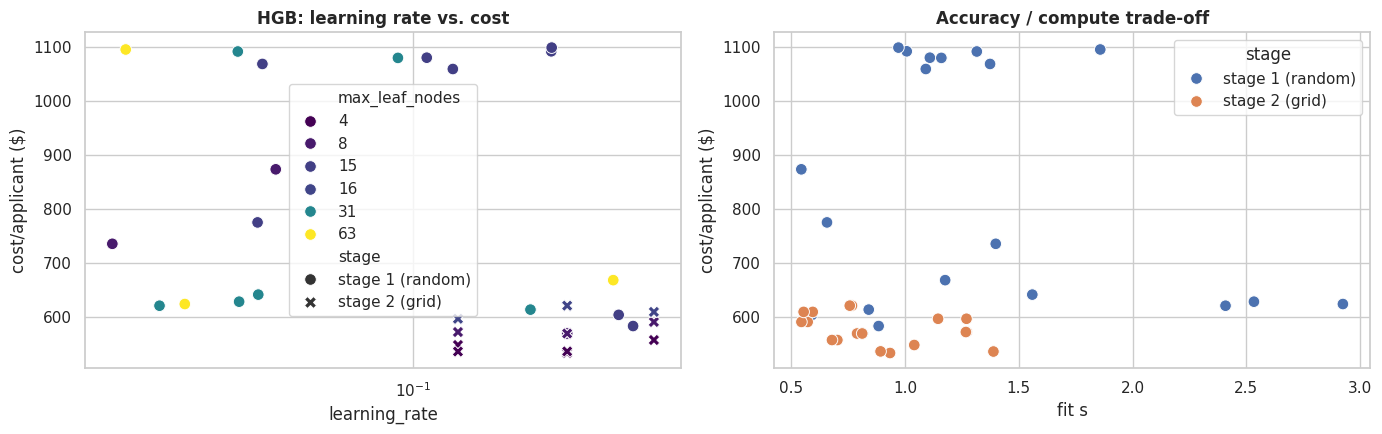

In [37]:
h1 = tidy(rs_hgb.cv_results_, ['model__learning_rate', 'model__max_leaf_nodes', 'model__max_iter', 'model__min_samples_leaf', 'model__l2_regularization', 'select']); h1['stage'] = 'stage 1 (random)'
h2 = tidy(gs_hgb.cv_results_, ['model__learning_rate', 'model__max_leaf_nodes', 'model__max_iter', 'model__min_samples_leaf', 'model__l2_regularization', 'select']); h2['stage'] = 'stage 2 (grid)'
hh = pd.concat([h1, h2], ignore_index=True)
print('Top 8 HGB configurations over both stages:'); display(hh.sort_values('cost/applicant ($)').head(8).round(4))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=hh, x='learning_rate', y='cost/applicant ($)', hue='max_leaf_nodes', style='stage', s=70, palette='viridis', ax=ax[0]); ax[0].set_xscale('log'); ax[0].set_title('HGB: learning rate vs. cost')
sns.scatterplot(data=hh, x='fit s', y='cost/applicant ($)', hue='stage', s=70, ax=ax[1]); ax[1].set_title('Accuracy / compute trade-off')
plt.tight_layout()


**What the search shows.** Stage 1 (20 random configurations) found that **shallow trees with a fairly high learning rate** work best (8 leaves, learning rate ≈ 0.21, 300 iterations, small leaves, L2 = 1, $568). Stage 2 refined around it and found that **even shallower trees (4 leaves)** improve further to **$532** per applicant (per-fold best threshold), a 6 % improvement over stage 1 for only 18 extra configurations (96 s). Feature selection never helped (every top configuration uses all features), and the cost/compute plot shows that the best configurations fit in about one second, so no expensive setting is needed. The tuned model's CV ROC-AUC rises from 0.991 to **0.994**, and the over-fitting gap is small (train 0.998 vs. CV 0.994) thanks to the shallow trees and regularisation.

**A note on the numbers:** the tuning figures ($655 and $532) pick the best threshold *within each fold*, which is slightly optimistic. The comparison table below recomputes everything from pooled out-of-fold predictions with one common threshold, which is the number to trust.

### 7c. Final candidates and selection


In [38]:
# ---------- Final candidates: tuned models + an ensemble of the two ----------
tuned_lr, tuned_hgb = gs_lr.best_estimator_, gs_hgb.best_estimator_
finalists = {
    'Tuned Logistic Regression': clone(tuned_lr),
    'Tuned Hist Gradient Boosting': clone(tuned_hgb),
    'Ensemble (tuned LR + tuned HGB)': VotingClassifier([('lr', clone(tuned_lr)), ('hgb', clone(tuned_hgb))], voting='soft'),
}
fin_rows, oof_final_store = [], {}
for name, est in finalists.items():
    oof, f = cv_evaluate(est, X_train, y_train)
    oof_final_store[name] = oof; fin_rows.append(summarize(name, oof, f, y_train))
fin_df = pd.DataFrame(fin_rows).set_index('Model')
untuned_ref = comparison.loc[['Logistic Regression', 'Hist Gradient Boosting', 'Voting Ensemble (LR+RF+HGB)']]
display(pd.concat([untuned_ref.rename(index=lambda s: s + ' (untuned)'), fin_df])[['ROC-AUC', 'ROC-AUC std', 'PR-AUC', 'Train ROC-AUC', 'Cost/appl @0.862 ($)', 'Best OOF threshold', 'Cost/appl @best ($)']].round(4))


,ROC-AUC,ROC-AUC std,PR-AUC,Train ROC-AUC,Cost/appl @0.862 ($),Best OOF threshold,Cost/appl @best ($)
Model,,,,,,,
Logistic Regression (untuned),0.9884,0.0013,0.9700,0.9891,688.500,0.820,684.500
Hist Gradient Boosting (untuned),0.9907,0.0020,0.9729,0.9995,687.000,0.840,667.875
Voting Ensemble (LR+RF+HGB) (untuned),0.9915,0.0018,0.9753,0.9993,848.875,0.720,629.875
Tuned Logistic Regression,0.9882,0.0013,0.9696,0.9889,712.500,0.815,677.000
Tuned Hist Gradient Boosting,0.9936,0.0009,0.9810,0.9983,608.375,0.810,557.750
Ensemble (tuned LR + tuned HGB),0.9934,0.0008,0.9806,0.9967,635.250,0.790,573.375


In [39]:
# ---------- Selection rule (documented BEFORE looking at the test set) ----------
# Regulators require explainable credit decisions, so we choose the SIMPLEST finalist whose cross-validated cost is within 5 % of the best.
interpretability_rank = ['Tuned Logistic Regression', 'Tuned Hist Gradient Boosting', 'Ensemble (tuned LR + tuned HGB)']   # simplest -> most complex
best_cost = fin_df['Cost/appl @best ($)'].min()
eligible = [m for m in interpretability_rank if fin_df.loc[m, 'Cost/appl @best ($)'] <= 1.05 * best_cost]
final_name = eligible[0]
print(f'Lowest CV cost: ${best_cost:,.1f}.  Models within 5 %: {eligible}')
print(f'==> FINAL MODEL: {final_name}')


Lowest CV cost: $557.8.  Models within 5 %: ['Tuned Hist Gradient Boosting', 'Ensemble (tuned LR + tuned HGB)']
==> FINAL MODEL: Tuned Hist Gradient Boosting


The tuned boosting model clearly improves on its untuned version (AUC 0.9907 → 0.9936; cost $668 → $558), while tuning did almost nothing for logistic regression ($685 → $677). The ensemble of the two tuned models does **not** beat tuned boosting alone ($573 vs. $558).

**Selection rule, set before touching the test set:** pick the *simplest* model whose cross-validated cost is within 5 % of the best. Only boosting (and the ensemble) qualify; logistic regression is 21 % more expensive ($677 vs. $558), which is too large a gap to give up for interpretability alone. **Final model: tuned Hist Gradient Boosting.** Its opacity is mitigated by permutation importance, a logistic-regression benchmark for explanations, and the review band recommended later.

## Evaluation and Conclusion
8. Conduct thorough evaluation of final model:
- Assess models test data performance using your defined metrics
- Analyze performance across different data segments
- Identify potential biases or limitations
- Visualize model performance
    - Classification: Confusion Matrix/ROC-AUC
    - Regression: Scatter Plot (Predicted vs. Actual values)

9. Extract and interpret feature importance/significance:
- Which features had the most impact on your model?
- Does this lead to any potential business recommendations?

10. Prepare your final deliverable:
- Technical notebook with complete analysis
- Executive summary for business stakeholders
- Recommendations for implementation
- Documentation of potential improvements

### 8a. Final model and decision threshold
The final model is refitted on the full training set. The approval threshold is chosen on the *training out-of-fold predictions* (a lightly smoothed cost curve), so the test set plays no part in it.


In [40]:
# ---------- Fit the final model on the full training set and fix the decision threshold ----------
final_pipe = clone(finalists[final_name]).fit(X_train, y_train)
oof_final = oof_final_store[final_name]

def smooth_best_threshold(y_true, p, window=5):
    """Cost-minimising threshold from a lightly smoothed cost curve (avoids chasing one noisy dip)."""
    c = pd.Series(cost_curve(y_true, p)).rolling(window, center=True, min_periods=1).mean().values
    i = int(c.argmin()); return float(THRESHOLDS[i]), float(c[i])

THRESH, oof_cost = smooth_best_threshold(y_train, oof_final)
print(f'Decision threshold chosen on TRAINING out-of-fold predictions: approve if P(creditworthy) >= {THRESH:.3f}')
print(f'(theoretical break-even for perfectly calibrated probabilities is {BAYES_T:.3f}); OOF cost/applicant = ${oof_cost:,.0f}')


Decision threshold chosen on TRAINING out-of-fold predictions: approve if P(creditworthy) >= 0.810
(theoretical break-even for perfectly calibrated probabilities is 0.862); OOF cost/applicant = $563


The chosen threshold (0.81) is a little below the theoretical break-even (0.862). The cost curve is very flat in this region (see below), so the difference is small; the data-driven threshold is used because it does not depend on the calibration assumption.

### 8b. Hold-out test performance (used once)


In [41]:
# ---------- Hold-out test evaluation (used ONCE) ----------
p_test = final_pipe.predict_proba(X_test)[:, 1]
y_t = y_test.values

def metrics_at(y_true, p, thr):
    pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_counts(y_true, pred)
    return {'threshold': thr, 'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred), 'False approvals': fp, 'False denials': fn,
            'Total cost ($)': business_cost(y_true, pred), 'Cost/applicant ($)': business_cost(y_true, pred) / len(y_true),
            'Net value vs deny-all ($)': net_value(y_true, pred)}

print(f'Test ROC-AUC = {roc_auc_score(y_t, p_test):.4f}   PR-AUC = {average_precision_score(y_t, p_test):.4f}\n')
test_tbl = pd.DataFrame({'Final model @ default 0.5': metrics_at(y_t, p_test, 0.5),
                         f'Final model @ break-even {BAYES_T:.3f}': metrics_at(y_t, p_test, BAYES_T),
                         f'Final model @ tuned {THRESH:.3f}': metrics_at(y_t, p_test, THRESH)}).T
for name, pred in [('Naive: approve everyone', np.ones_like(y_t)), ('Naive: deny everyone', np.zeros_like(y_t))]:
    tn, fp, fn, tp = confusion_counts(y_t, pred)
    test_tbl.loc[name] = [np.nan, precision_score(y_t, pred, zero_division=0), recall_score(y_t, pred), f1_score(y_t, pred, zero_division=0), fp, fn,
                          business_cost(y_t, pred), business_cost(y_t, pred) / len(y_t), net_value(y_t, pred)]
display(test_tbl.round(3))


Test ROC-AUC = 0.9944   PR-AUC = 0.9840



,threshold,Precision,Recall,F1,False approvals,False denials,Total cost ($),Cost/applicant ($),Net value vs deny-all ($)
Final model @ default 0.5,0.500,0.943,0.931,0.937,54.0,66.0,3228000.0,807.0,4420000.0
Final model @ break-even 0.862,0.862,0.994,0.743,0.850,4.0,246.0,2168000.0,542.0,5480000.0
Final model @ tuned 0.810,0.810,0.987,0.785,0.874,10.0,206.0,2148000.0,537.0,5500000.0
Naive: approve everyone,NaN,0.239,1.000,0.386,3044.0,0.0,152200000.0,38050.0,-144552000.0
Naive: deny everyone,NaN,0.000,0.000,0.000,0.0,956.0,7648000.0,1912.0,0.0


In [42]:
# ---------- Did we meet the targets set in the Business Understanding phase? ----------
m = metrics_at(y_t, p_test, THRESH)
tgt = pd.DataFrame([
    ['ROC-AUC', '>= 0.90 (stretch 0.95)', f'{roc_auc_score(y_t, p_test):.3f}', roc_auc_score(y_t, p_test) >= 0.95],
    ['Precision of approvals', '>= 0.90', f"{m['Precision']:.3f}", m['Precision'] >= 0.90],
    ['Recall of good applicants', '>= 0.60', f"{m['Recall']:.3f}", m['Recall'] >= 0.60],
    ['Cost per applicant', f'<= ${0.5 * best_naive_cost:,.0f}', f"${m['Cost/applicant ($)']:,.0f}", m['Cost/applicant ($)'] <= 0.5 * best_naive_cost]],
    columns=['Metric', 'Target', 'Achieved (test)', 'Met?']).set_index('Metric')
tgt['Met?'] = tgt['Met?'].map({True: 'YES', False: 'NO'})
tgt


,Target,Achieved (test),Met?
Metric,,,
ROC-AUC,>= 0.90 (stretch 0.95),0.994,YES
Precision of approvals,>= 0.90,0.987,YES
Recall of good applicants,>= 0.60,0.785,YES
Cost per applicant,<= $956,$537,YES


**All four targets are met, with a wide margin.**

- **ROC-AUC 0.994** and PR-AUC 0.984: excellent ranking. Test numbers agree closely with cross-validation (0.9936), so there is no sign of over-fitting.
- **Precision 0.987:** of 760 approvals only 10 were bad loans ($500 k). **Recall 0.785:** the model approves 750 of the 956 good applicants and misses 206 ($1.65 M).
- **Cost $537 per applicant**, vs. $807 at the default 0.5 threshold and $1,912 for deny-all. The break-even threshold (0.862) gives $542, nearly identical, consistent with well-calibrated probabilities (the calibration plot below agrees).

### 8c. Visual evaluation


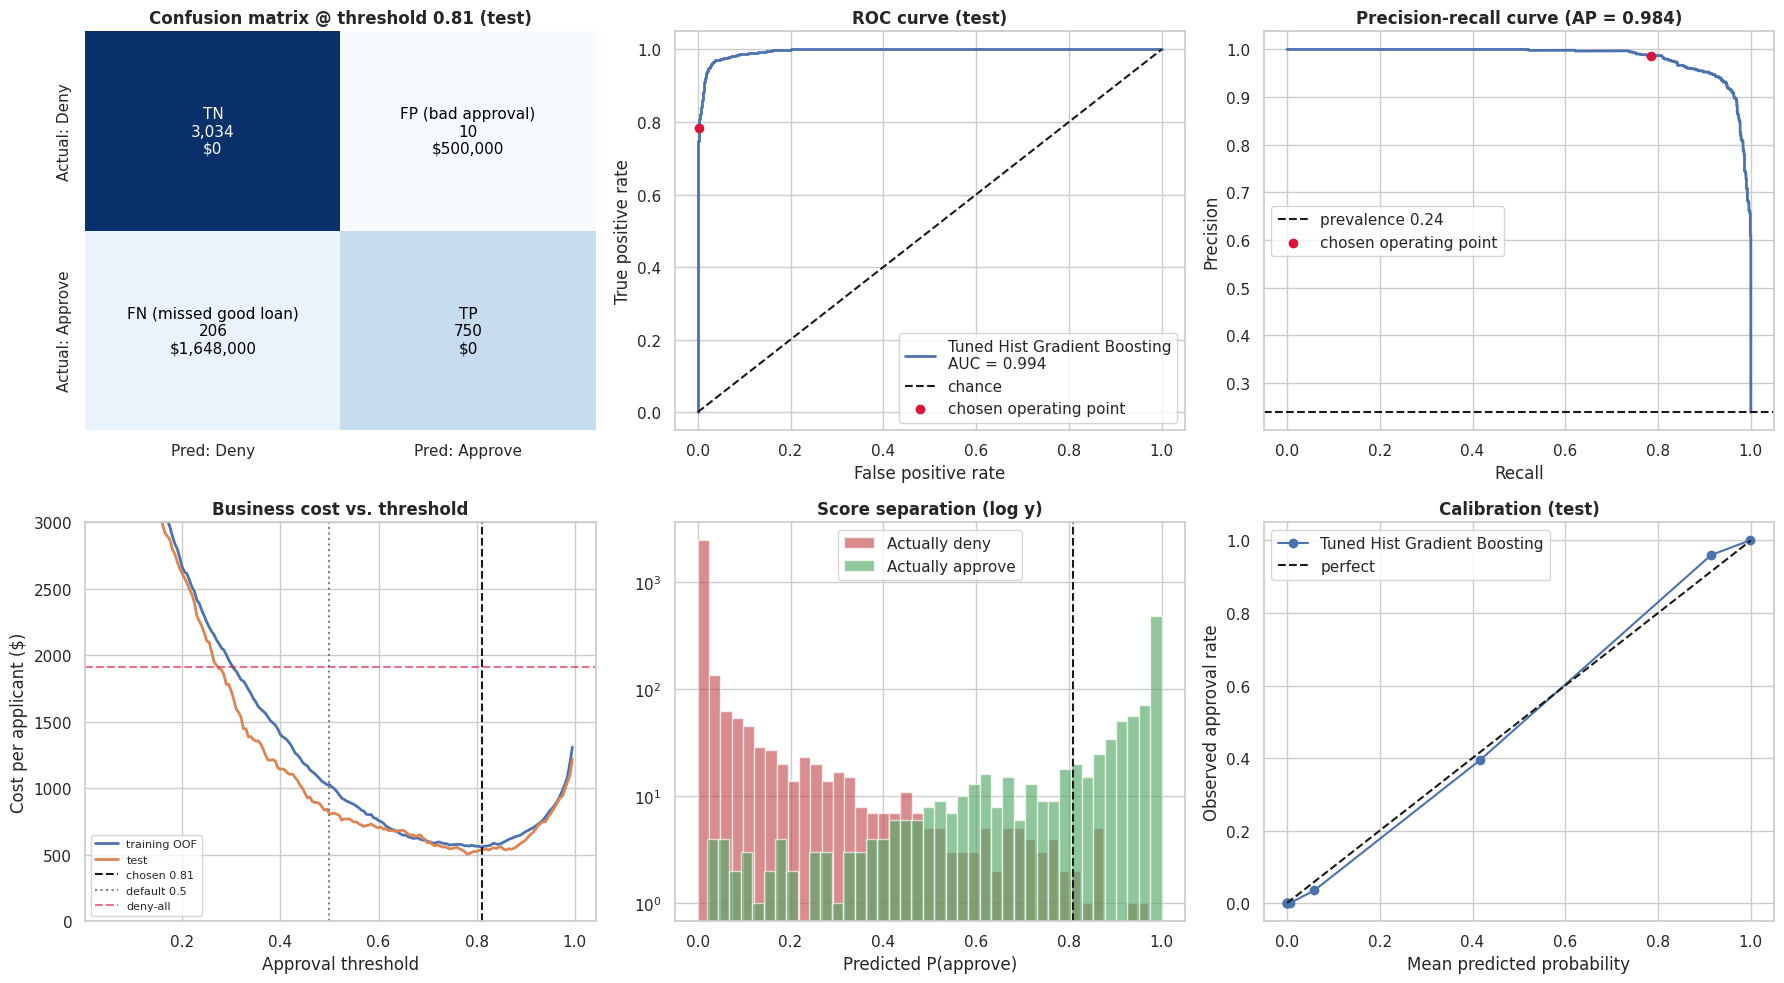

In [43]:
fig, ax = plt.subplots(2, 3, figsize=(18, 10))
# (1) confusion matrix with dollar impact
pred_t = (p_test >= THRESH).astype(int); tn, fp, fn, tp = confusion_counts(y_t, pred_t)
cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(cm, annot=False, cmap='Blues', cbar=False, ax=ax[0, 0], xticklabels=['Pred: Deny', 'Pred: Approve'], yticklabels=['Actual: Deny', 'Actual: Approve'])
labels = [[f'TN\n{tn:,}\n$0', f'FP (bad approval)\n{fp:,}\n${fp * COST_FP:,.0f}'], [f'FN (missed good loan)\n{fn:,}\n${fn * COST_FN:,.0f}', f'TP\n{tp:,}\n$0']]
for i in range(2):
    for j in range(2): ax[0, 0].text(j + .5, i + .5, labels[i][j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=11)
ax[0, 0].set_title(f'Confusion matrix @ threshold {THRESH:.2f} (test)')
# (2) ROC
fpr, tpr, _ = roc_curve(y_t, p_test); ax[0, 1].plot(fpr, tpr, lw=2, label=f'{final_name}\nAUC = {roc_auc_score(y_t, p_test):.3f}'); ax[0, 1].plot([0, 1], [0, 1], 'k--', label='chance')
ax[0, 1].scatter([fp / (fp + tn)], [tp / (tp + fn)], color='crimson', zorder=5, label='chosen operating point'); ax[0, 1].set_xlabel('False positive rate'); ax[0, 1].set_ylabel('True positive rate'); ax[0, 1].set_title('ROC curve (test)'); ax[0, 1].legend(loc='lower right')
# (3) Precision-recall
pr, rc, _ = precision_recall_curve(y_t, p_test); ax[0, 2].plot(rc, pr, lw=2); ax[0, 2].axhline(y_t.mean(), color='k', ls='--', label=f'prevalence {y_t.mean():.2f}')
ax[0, 2].scatter([tp / (tp + fn)], [tp / (tp + fp)], color='crimson', zorder=5, label='chosen operating point'); ax[0, 2].set_xlabel('Recall'); ax[0, 2].set_ylabel('Precision'); ax[0, 2].set_title(f'Precision-recall curve (AP = {average_precision_score(y_t, p_test):.3f})'); ax[0, 2].legend()
# (4) cost vs threshold: test and training OOF
ax[1, 0].plot(THRESHOLDS, cost_curve(y_train, oof_final), label='training OOF', lw=2); ax[1, 0].plot(THRESHOLDS, cost_curve(y_t, p_test), label='test', lw=2)
ax[1, 0].axvline(THRESH, color='k', ls='--', label=f'chosen {THRESH:.2f}'); ax[1, 0].axvline(.5, color='gray', ls=':', label='default 0.5'); ax[1, 0].axhline(best_naive_cost, color='crimson', ls='--', alpha=.6, label='deny-all')
ax[1, 0].set_ylim(0, 3000); ax[1, 0].set_xlabel('Approval threshold'); ax[1, 0].set_ylabel('Cost per applicant ($)'); ax[1, 0].set_title('Business cost vs. threshold'); ax[1, 0].legend(fontsize=8)
# (5) predicted-probability distribution
ax[1, 1].hist(p_test[y_t == 0], bins=40, alpha=.65, color='#c44e52', label='Actually deny'); ax[1, 1].hist(p_test[y_t == 1], bins=40, alpha=.65, color='#55a868', label='Actually approve')
ax[1, 1].axvline(THRESH, color='k', ls='--'); ax[1, 1].set_yscale('log'); ax[1, 1].set_xlabel('Predicted P(approve)'); ax[1, 1].set_title('Score separation (log y)'); ax[1, 1].legend()
# (6) calibration
frac, mean_p = calibration_curve(y_t, p_test, n_bins=10, strategy='quantile'); ax[1, 2].plot(mean_p, frac, marker='o', label=final_name); ax[1, 2].plot([0, 1], [0, 1], 'k--', label='perfect')
ax[1, 2].set_xlabel('Mean predicted probability'); ax[1, 2].set_ylabel('Observed approval rate'); ax[1, 2].set_title('Calibration (test)'); ax[1, 2].legend()
plt.tight_layout()


The confusion matrix shows the intended asymmetry: **very few expensive false approvals (10)** and a larger number of cheap false denials (206). The ROC and precision-recall curves hug the top-left corner, and the cost-vs-threshold curve has a wide, flat minimum between roughly 0.65 and 0.9 (the training and test curves agree), so the exact threshold is not fragile. The score histogram shows that most denied applicants receive near-zero scores and most approved applicants receive scores near 1; the overlap is confined to the mid-range. The calibration curve lies on the diagonal.


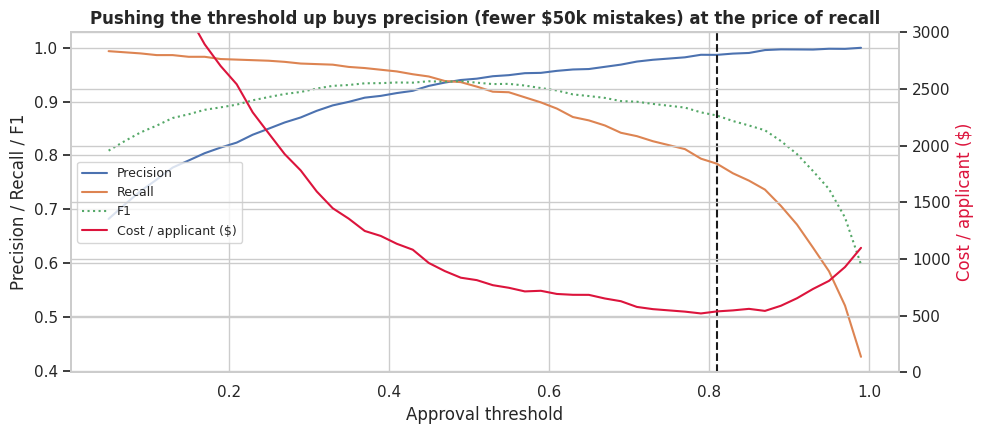

In [44]:
# ---------- Metric trade-offs across thresholds (visual) ----------
rows = []
for t in THRESHOLDS[::4]:
    mm = metrics_at(y_t, p_test, t); rows.append({'t': t, 'Precision': mm['Precision'], 'Recall': mm['Recall'], 'F1': mm['F1'], 'cost': mm['Cost/applicant ($)']})
tr = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4.5)); ax2 = ax.twinx()
ax.plot(tr.t, tr.Precision, label='Precision'); ax.plot(tr.t, tr.Recall, label='Recall'); ax.plot(tr.t, tr.F1, label='F1', ls=':')
ax2.plot(tr.t, tr.cost, color='crimson', label='Cost / applicant ($)'); ax2.set_ylim(0, 3000); ax2.set_ylabel('Cost / applicant ($)', color='crimson')
ax.axvline(THRESH, color='k', ls='--'); ax.set_xlabel('Approval threshold'); ax.set_ylabel('Precision / Recall / F1'); ax.set_title('Pushing the threshold up buys precision (fewer $50k mistakes) at the price of recall')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc='center left', fontsize=9)
plt.tight_layout()


This is the visual summary of the metric trade-offs: raising the threshold buys precision (fewer $50 k mistakes) at the price of recall, and the cost curve (red) bottoms out near the chosen 0.81. F1, which treats both errors equally, would favour a *lower* threshold than the business wants (F1 is 0.937 at 0.5 but 0.874 at 0.81, even though cost is much lower at 0.81).

### 8d. Dollar-value impact


In [45]:
# ---------- Dollar-value impact (test set of 4,000 applicants, scaled to 10,000 and 100,000 applications) ----------
def policy_row(name, pred):
    tn, fp, fn, tp = confusion_counts(y_t, pred); n = len(y_t)
    return {'Policy': name, 'Loss from false approvals ($)': fp * COST_FP, 'Loss from false denials ($)': fn * COST_FN, 'Total cost ($)': fp * COST_FP + fn * COST_FN,
            'Cost / applicant ($)': (fp * COST_FP + fn * COST_FN) / n, 'Net value vs deny-all ($)': net_value(y_t, pred)}
impact = pd.DataFrame([policy_row('Approve everyone', np.ones_like(y_t)), policy_row('Deny everyone', np.zeros_like(y_t)),
                       policy_row('Model @ default 0.5', (p_test >= .5).astype(int)), policy_row(f'Model @ tuned {THRESH:.2f}', (p_test >= THRESH).astype(int))]).set_index('Policy')
display(impact.round(0))
c_model = impact.loc[f'Model @ tuned {THRESH:.2f}', 'Cost / applicant ($)']; c_deny = impact.loc['Deny everyone', 'Cost / applicant ($)']; c_def = impact.loc['Model @ default 0.5', 'Cost / applicant ($)']
print(f'\nSaving vs best naive policy (deny all): ${c_deny - c_model:,.0f} per applicant ({1 - c_model / c_deny:.0%})')
print(f'Saving of tuned threshold vs default 0.5 threshold: ${c_def - c_model:,.0f} per applicant ({1 - c_model / c_def:.0%})')
for n_app in (10_000, 100_000):
    print(f'  per {n_app:>7,} applications: model cost ${c_model * n_app:,.0f}  vs deny-all ${c_deny * n_app:,.0f}  -> saves ${(c_deny - c_model) * n_app:,.0f}')


,Loss from false approvals ($),Loss from false denials ($),Total cost ($),Cost / applicant ($),Net value vs deny-all ($)
Policy,,,,,
Approve everyone,152200000,0,152200000,38050.0,-144552000
Deny everyone,0,7648000,7648000,1912.0,0
Model @ default 0.5,2700000,528000,3228000,807.0,4420000
Model @ tuned 0.81,500000,1648000,2148000,537.0,5500000



Saving vs best naive policy (deny all): $1,375 per applicant (72%)
Saving of tuned threshold vs default 0.5 threshold: $270 per applicant (33%)
  per  10,000 applications: model cost $5,370,000  vs deny-all $19,120,000  -> saves $13,750,000
  per 100,000 applications: model cost $53,700,000  vs deny-all $191,200,000  -> saves $137,500,000


On the 4,000 test applicants the model's total cost of wrong decisions is **$2.15 M** vs. **$7.65 M** for denying everyone and **$152 M** for approving everyone. Relative to denying everyone, the model creates **$5.5 M of net value** (captured profit on 750 good loans minus the loss on 10 bad ones). Per 10,000 applications that is about **$13.75 M**. Choosing the cost-optimal threshold instead of 0.5 is worth another **$270 per applicant** (33 %) without changing the model at all.

*Reminder:* these are relative to the historical approval decisions, not to observed repayment (see Limitations).


### 8e. Implementation option: auto-approve / manual review / auto-deny
Because the model is very confident at the extremes, a three-way policy lets loan officers focus on the genuinely uncertain files. The table varies the lower edge of the review band (the upper edge stays at the 0.81 approval threshold). The cost column is an *upper bound*: it assumes reviewers decide the review band perfectly.


In [46]:
# ---------- Implementation option: 3-way policy (auto-approve / manual review / auto-deny) ----------
# The model is most confident at the extremes; a review band lets loan officers spend time where the model is unsure.
# Numbers below are an UPPER BOUND on the benefit (they assume reviewers decide the review band perfectly).
rows = []
for t_low in [0.2, 0.3, 0.4, 0.5]:
    auto_app = p_test >= THRESH; auto_deny = p_test < t_low; review = ~auto_app & ~auto_deny
    rows.append({'review band (P between)': f'{t_low:.1f} - {THRESH:.2f}', '% auto-approved': auto_app.mean() * 100, '% manual review': review.mean() * 100, '% auto-denied': auto_deny.mean() * 100,
                 'bad loans auto-approved': int(((y_t == 0) & auto_app).sum()), 'good loans auto-denied': int(((y_t == 1) & auto_deny).sum()),
                 'good / bad applicants in review band': f"{int(((y_t == 1) & review).sum())} / {int(((y_t == 0) & review).sum())}",
                 'cost/applicant if reviewers are perfect ($)': (COST_FP * ((y_t == 0) & auto_app).sum() + COST_FN * ((y_t == 1) & auto_deny).sum()) / len(y_t)})
display(pd.DataFrame(rows).set_index('review band (P between)').round(1))


,% auto-approved,% manual review,% auto-denied,bad loans auto-approved,good loans auto-denied,good / bad applicants in review band,cost/applicant if reviewers are perfect ($)
review band (P between),,,,,,,
0.2 - 0.81,19.0,9.6,71.4,10,20,186 / 196,165.0
0.3 - 0.81,19.0,7.6,73.4,10,28,178 / 124,181.0
0.4 - 0.81,19.0,6.0,75.0,10,40,166 / 75,205.0
0.5 - 0.81,19.0,4.6,76.4,10,66,140 / 44,257.0


About **19 % of applicants are auto-approved** with only 10 bad loans among them. With a review band from 0.3 to 0.81, **7.6 % of applicants (about 300 of 4,000 files) go to a loan officer**, 73 % are auto-denied (with 28 good loans lost), and the cost falls from $537 to at most **$181 per applicant** if reviewers resolve the band perfectly. Even that band contains a mix (178 good vs. 124 bad applicants), which is exactly where human judgement adds value. Real reviewers will not be perfect, so the true saving lies between $181 and $537; this should be measured in a pilot.

### 8f. Performance across data segments


In [47]:
# ---------- Performance across data segments ----------
def seg_table(by, name):
    d = pd.DataFrame({'seg': by.values, 'y': y_t, 'p': (p_test >= THRESH).astype(int), 's': p_test}); rows = []
    for g, s in d.groupby('seg', observed=True):
        tn, fp, fn, tp = confusion_counts(s.y, s.p)
        rows.append({name: g, 'n': len(s), 'actual approve rate': s.y.mean(), 'predicted approve rate': s.p.mean(), 'precision': tp / (tp + fp) if tp + fp else np.nan,
                     'recall (TPR)': tp / (tp + fn) if tp + fn else np.nan, 'FPR': fp / (fp + tn) if fp + tn else np.nan, 'false approvals': fp, 'false denials': fn,
                     'cost/applicant ($)': (fp * COST_FP + fn * COST_FN) / len(s), 'AUC': roc_auc_score(s.y, s.s) if s.y.nunique() > 1 else np.nan})
    return pd.DataFrame(rows).set_index(name)

seg_defs = {
    'EmploymentStatus': X_test['EmploymentStatus'],
    'EducationLevel': X_test['EducationLevel'].fillna('<missing>'),
    'MaritalStatus': X_test['MaritalStatus'].fillna('<missing>'),
    'HomeOwnership': X_test['HomeOwnershipStatus'],
    'LoanPurpose': X_test['LoanPurpose'],
    'AgeBand': pd.cut(X_test['Age'], [17, 29, 44, 59, 120], labels=['18-29', '30-44', '45-59', '60+']),
    'IncomeQuartile': pd.qcut(X_test['MonthlyIncome'], 4, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)']),
    'LoanSize': pd.qcut(X_test['LoanAmount'], 3, labels=['small', 'medium', 'large']),
    'CreditScoreBand': pd.cut(X_test['CreditScore'], [0, 540, 580, 620, 900], labels=['<540', '540-579', '580-619', '620+']),
}
seg_results = {k: seg_table(v, k) for k, v in seg_defs.items()}
for k in ['EmploymentStatus', 'EducationLevel', 'AgeBand', 'IncomeQuartile', 'CreditScoreBand']:
    print(f'--- {k} ---'); display(seg_results[k].round(3))


--- EmploymentStatus ---


,n,actual approve rate,predicted approve rate,precision,recall (TPR),FPR,false approvals,false denials,cost/applicant ($),AUC
EmploymentStatus,,,,,,,,,,
Employed,3402,0.242,0.192,0.986,0.783,0.003,9,179,553.204,0.995
Self-Employed,311,0.264,0.212,1.000,0.805,0.000,0,16,411.576,0.994
Unemployed,287,0.174,0.139,0.975,0.780,0.004,1,11,480.836,0.994


--- EducationLevel ---


,n,actual approve rate,predicted approve rate,precision,recall (TPR),FPR,false approvals,false denials,cost/applicant ($),AUC
EducationLevel,,,,,,,,,,
<missing>,193,0.000,0.000,NaN,NaN,0.000,0,0,0.000,NaN
Associate,782,0.207,0.157,0.976,0.741,0.005,3,42,621.483,0.993
Bachelor,1163,0.279,0.227,0.992,0.806,0.002,2,63,519.347,0.994
Doctorate,156,0.442,0.385,1.000,0.870,0.000,0,9,461.538,0.992
High School,1086,0.153,0.114,0.984,0.735,0.002,2,44,416.206,0.995
Master,620,0.377,0.305,0.984,0.795,0.008,3,48,861.290,0.992


--- AgeBand ---


,n,actual approve rate,predicted approve rate,precision,recall (TPR),FPR,false approvals,false denials,cost/applicant ($),AUC
AgeBand,,,,,,,,,,
18-29,773,0.133,0.106,0.963,0.767,0.004,3,24,442.432,0.993
30-44,1877,0.242,0.185,0.991,0.758,0.002,3,110,548.748,0.993
45-59,1152,0.285,0.234,0.993,0.814,0.002,2,61,510.417,0.998
60+,198,0.359,0.313,0.968,0.845,0.016,2,11,949.495,0.992


--- IncomeQuartile ---


,n,actual approve rate,predicted approve rate,precision,recall (TPR),FPR,false approvals,false denials,cost/applicant ($),AUC
IncomeQuartile,,,,,,,,,,
Q1 (lowest),1000,0.014,0.008,0.875,0.500,0.001,1,7,106.0,0.992
Q2,1000,0.072,0.042,1.000,0.583,0.000,0,30,240.0,0.992
Q3,1000,0.225,0.155,0.981,0.676,0.004,3,73,734.0,0.988
Q4 (highest),1000,0.645,0.555,0.989,0.851,0.017,6,96,1068.0,0.990


--- CreditScoreBand ---


,n,actual approve rate,predicted approve rate,precision,recall (TPR),FPR,false approvals,false denials,cost/applicant ($),AUC
CreditScoreBand,,,,,,,,,,
<540,1008,0.168,0.115,1.000,0.686,0.000,0,53,420.635,0.993
540-579,1047,0.224,0.181,0.989,0.796,0.002,2,48,462.273,0.994
580-619,1300,0.246,0.197,0.984,0.788,0.004,4,68,572.308,0.996
620+,645,0.360,0.309,0.980,0.841,0.010,4,37,768.992,0.993


- **Ranking quality is uniform:** AUC is at least 0.988 in every segment shown, so the model does not "fall apart" for any group.
- **Precision stays high everywhere** (≥ 0.96 in all employment, education, age and credit-score groups). The only lower value is the lowest-income quartile (0.875), which rests on just 8 approvals and 1 error.
- **Recall depends on income:** the model catches 85 % of good applicants in the top income quartile but only 50–68 % in the lower three quartiles. Low-income good applicants are rare (1.4 % of the lowest quartile are approved at all) and sit close to the boundary, so the cautious threshold leaves more of them out. This is the main place where the model is *more conservative than the historical process*.
- **Cost per applicant** is highest where most approvals happen (top income quartile $1,068) and for applicants aged 60+ ($949; only 198 applicants and 2 bad approvals, so this is noisy). Master's-degree holders also have a high cost ($861). Employment and credit-score groups look similar.
- **Missing education:** all 193 test applicants were (correctly, per the historical pattern) denied: the model has learned the process rule.


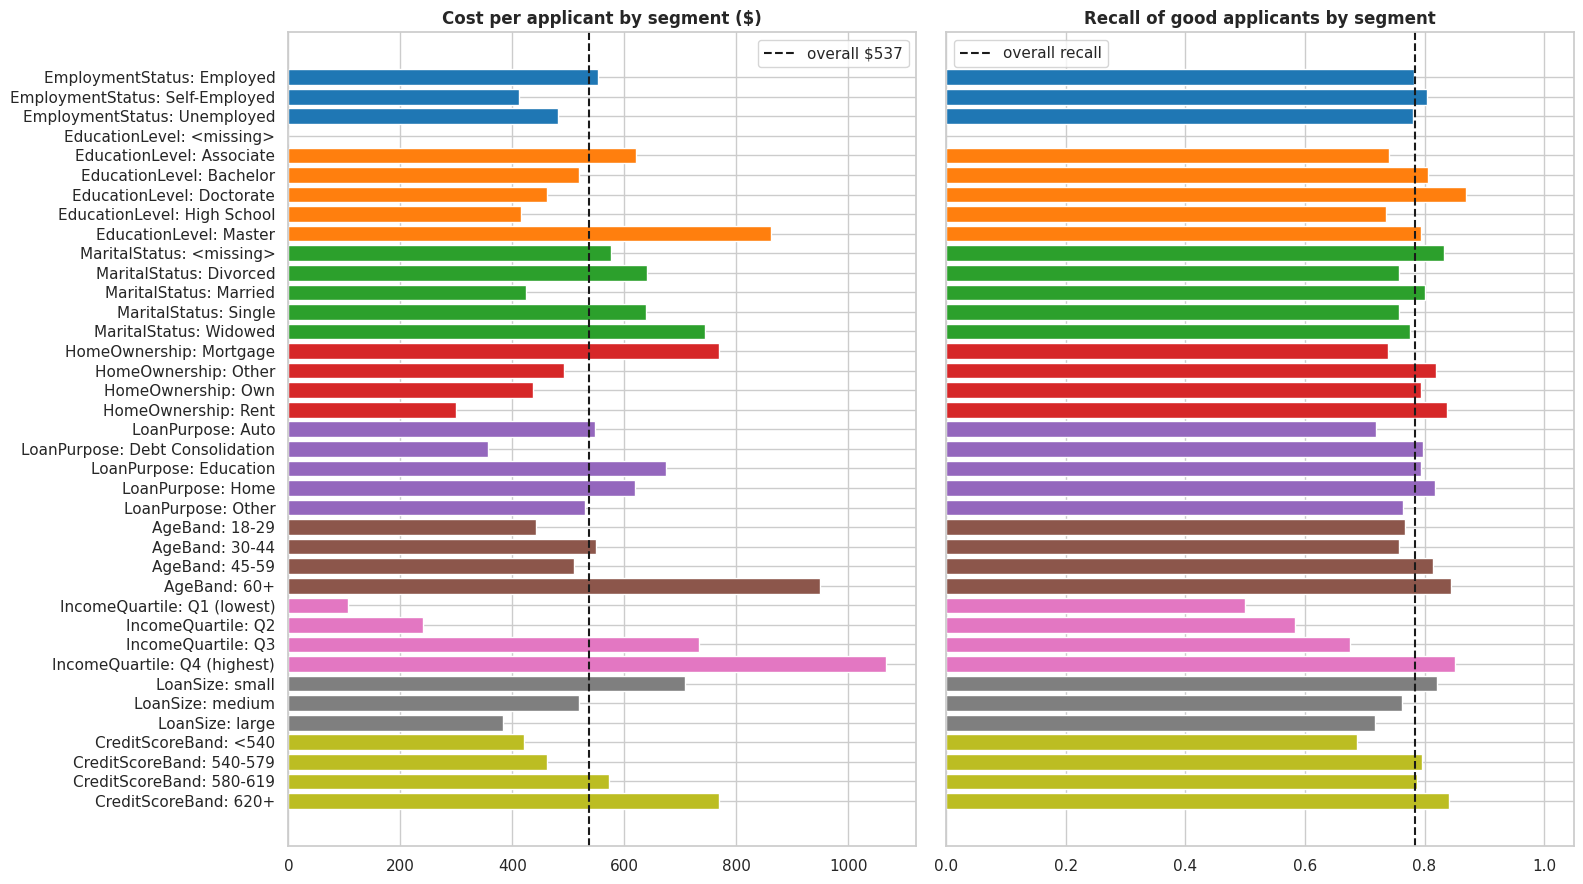

In [48]:
all_seg = pd.concat([t.reset_index().rename(columns={t.index.name: 'segment'}).assign(feature=t.index.name) for t in seg_results.values()], ignore_index=True)
all_seg['label'] = all_seg['feature'] + ': ' + all_seg['segment'].astype(str)
fig, ax = plt.subplots(1, 2, figsize=(16, 9), sharey=True)
colors = sns.color_palette('tab10', n_colors=len(seg_defs)); cmap = {f: colors[i] for i, f in enumerate(seg_defs)}
ax[0].barh(all_seg['label'], all_seg['cost/applicant ($)'], color=[cmap[f] for f in all_seg['feature']]); ax[0].axvline(c_model, color='k', ls='--', label=f'overall ${c_model:,.0f}')
ax[0].invert_yaxis(); ax[0].set_title('Cost per applicant by segment ($)'); ax[0].legend()
ax[1].barh(all_seg['label'], all_seg['recall (TPR)'], color=[cmap[f] for f in all_seg['feature']]); ax[1].axvline(recall_score(y_t, (p_test >= THRESH).astype(int)), color='k', ls='--', label='overall recall')
ax[1].set_title('Recall of good applicants by segment'); ax[1].set_xlim(0, 1.05); ax[1].legend()
plt.tight_layout()


### 8g. Bias and fairness
Age and marital status are legally sensitive in lending. Here is how the model behaves across those groups.


In [49]:
# ---------- Bias / fairness diagnostics on attributes that are legally sensitive in lending (age, marital status) ----------
def fairness_view(feature):
    t = seg_results[feature][['n', 'actual approve rate', 'predicted approve rate', 'recall (TPR)', 'FPR']].copy()
    t['model/actual approve ratio'] = t['predicted approve rate'] / t['actual approve rate']
    return t
for f in ['AgeBand', 'MaritalStatus']:
    ft = fairness_view(f); print(f'--- {f} ---'); display(ft.round(3))
    pr = ft['predicted approve rate']; print(f'Disparate-impact ratio (lowest / highest predicted approval rate): {pr.min() / pr.max():.2f}   (the common "four-fifths" screen is 0.80)')
    print(f'Equal-opportunity gap (max - min recall): {ft["recall (TPR)"].max() - ft["recall (TPR)"].min():.3f}   |   FPR gap: {ft["FPR"].max() - ft["FPR"].min():.3f}\n')


--- AgeBand ---


,n,actual approve rate,predicted approve rate,recall (TPR),FPR,model/actual approve ratio
AgeBand,,,,,,
18-29,773,0.133,0.106,0.767,0.004,0.796
30-44,1877,0.242,0.185,0.758,0.002,0.764
45-59,1152,0.285,0.234,0.814,0.002,0.820
60+,198,0.359,0.313,0.845,0.016,0.873


Disparate-impact ratio (lowest / highest predicted approval rate): 0.34   (the common "four-fifths" screen is 0.80)
Equal-opportunity gap (max - min recall): 0.087   |   FPR gap: 0.014

--- MaritalStatus ---


,n,actual approve rate,predicted approve rate,recall (TPR),FPR,model/actual approve ratio
MaritalStatus,,,,,,
<missing>,267,0.292,0.247,0.833,0.005,0.846
Divorced,506,0.227,0.176,0.757,0.005,0.774
Married,1911,0.234,0.188,0.801,0.001,0.805
Single,1152,0.240,0.185,0.757,0.005,0.772
Widowed,164,0.244,0.195,0.775,0.008,0.800


Disparate-impact ratio (lowest / highest predicted approval rate): 0.71   (the common "four-fifths" screen is 0.80)
Equal-opportunity gap (max - min recall): 0.077   |   FPR gap: 0.007



- **Age:** the model's approval rate is lower than the historical rate in *every* age band (76 %–87 % of it), so it is uniformly more cautious rather than singling out one group. The 0.34 min/max ratio between age bands mostly reflects genuinely different *historical* approval rates (13 % for 18–29 vs. 36 % for 60+, driven by income), not a distortion added by the model. Recall differs by 8.7 percentage points (0.76 for ages 30–44 vs. 0.85 for 60+) and the false-approval rate is highest for 60+ (1.6 %, 2 errors among 198 applicants, so small-sample caution applies).
- **Marital status:** historical approval rates are nearly identical across groups (23 %–24 %) apart from the small "missing" group (29 %), and predicted rates are also close. The 0.71 ratio is created by the 267-applicant "missing" group; excluding it the ratio is about 0.90.
- **Education** (a frequently scrutinised "alternative" variable) is important to the model (see below), and missing education is always denied. That deserves a compliance review.

**Mitigation experiment.** I retrained the identical pipeline without the sensitive attributes, and also without `Experience` (0.98 correlated with `Age`, so a proxy).


In [50]:
# ---------- Bias mitigation experiment: remove legally sensitive attributes (and a proxy) and measure the price ----------
def without_columns(est, exclude):
    """Copy of a (tuned) pipeline whose preprocessor no longer sees the given raw columns. Keeps every tuned setting."""
    est = clone(est)
    if isinstance(est, VotingClassifier):
        return VotingClassifier([(n, without_columns(e, exclude)) for n, e in est.estimators], voting=est.voting)
    new_tr = [(n, t, [c for c in cols if c not in exclude]) for n, t, cols in est.named_steps['prep'].transformers]
    est.set_params(prep__transformers=[x for x in new_tr if len(x[2]) > 0])
    return est

def evaluate_variant(label, est):
    oof, f = cv_evaluate(est, X_train, y_train); thr, _ = smooth_best_threshold(y_train, oof)
    mdl = clone(est).fit(X_train, y_train); p = mdl.predict_proba(X_test)[:, 1]; pred = (p >= thr).astype(int)
    age_rate = pd.Series(pred).groupby(seg_defs['AgeBand'].values, observed=True).mean(); mar_rate = pd.Series(pred).groupby(seg_defs['MaritalStatus'].values).mean()
    return {'Variant': label, 'CV ROC-AUC': f['roc_auc'].mean(), 'Test ROC-AUC': roc_auc_score(y_t, p), 'Threshold': thr,
            'Test cost/applicant ($)': business_cost(y_t, pred) / len(y_t), 'Age-band approval ratio (min/max)': age_rate.min() / age_rate.max(),
            'Marital approval ratio (min/max)': mar_rate.min() / mar_rate.max()}
variants = [evaluate_variant('Final model (all features)', finalists[final_name]),
            evaluate_variant('Without Age & MaritalStatus', without_columns(finalists[final_name], ['Age', 'MaritalStatus'])),
            evaluate_variant('Without Age, Experience (age proxy) & MaritalStatus', without_columns(finalists[final_name], ['Age', 'Experience', 'MaritalStatus']))]
variants_df = pd.DataFrame(variants).set_index('Variant'); variants_df.round(4)


,CV ROC-AUC,Test ROC-AUC,Threshold,Test cost/applicant ($),Age-band approval ratio (min/max),Marital approval ratio (min/max)
Variant,,,,,,
Final model (all features),0.9936,0.9944,0.810,537.0,0.3388,0.7116
Without Age & MaritalStatus,0.9936,0.9946,0.820,553.0,0.3293,0.7225
"Without Age, Experience (age proxy) & MaritalStatus",0.9922,0.9930,0.845,640.0,0.3842,0.8054


Removing `Age` and `MaritalStatus` is **almost free**: test AUC is unchanged (0.9946 vs. 0.9944) and cost rises by only $16 per applicant (+3 %). The model barely used them (their permutation importance below is about zero). Also removing the proxy `Experience` costs more ($640, +19 %) and improves the age-band ratio only from 0.34 to 0.38, while lifting the marital-status ratio above the 0.80 screen (0.81). **Recommendation:** drop `Age` and `MaritalStatus` from the production model now; discuss `Experience` and `EducationLevel` with compliance, weighing the extra cost (about $100 per applicant) against the regulatory risk. The submitted final model remains the one selected by cross-validation (the experiment is a post-hoc diagnostic, not used for selection).

### 9. Feature importance


,AUC drop when shuffled,AUC drop std,Extra cost/applicant when shuffled ($),cost std
MonthlyIncome,0.1454,0.0035,2862.3125,169.5011
InterestRate,0.0513,0.0019,1711.8750,77.9093
TotalDebtToIncomeRatio,0.0314,0.0018,743.4375,65.2119
LoanAmount,0.0268,0.0011,805.8125,39.9593
BaseInterestRate,0.0137,0.0009,700.8750,67.8412
NetWorth,0.0093,0.0006,279.4375,63.9196
LengthOfCreditHistory,0.0091,0.0005,394.7500,45.4230
EducationLevel,0.0089,0.0009,299.8750,46.5119
BankruptcyHistory,0.0061,0.0007,294.6875,17.5730
LoanDuration,0.0057,0.0005,268.5625,36.0490


Features with ~zero importance (|AUC drop| < 0.0005): ['MonthlyDebtPayments', 'CreditScore', 'TotalLiabilities', 'MonthlyLoanPayment', 'SavingsAccountBalance', 'CheckingAccountBalance', 'MaritalStatus', 'DebtToIncomeRatio', 'NumberOfDependents', 'UtilityBillsPaymentHistory', 'CreditCardUtilizationRate', 'AnnualIncome', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'JobTenure', 'LoanPurpose']


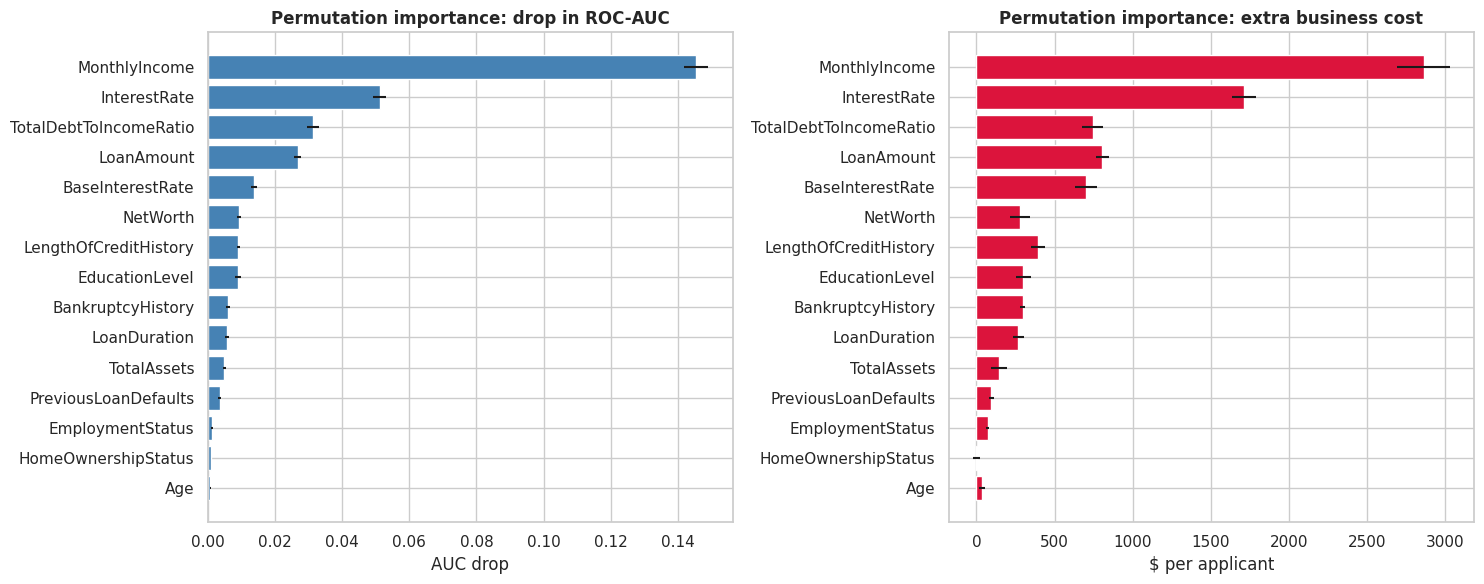

In [51]:
# ---------- Feature importance: permutation importance on the held-out test set (model-agnostic, on the RAW features) ----------
perm_auc = permutation_importance(final_pipe, X_test, y_test, scoring='roc_auc', n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1)
perm_cost = permutation_importance(final_pipe, X_test, y_test, scoring=lambda est, X, y: cost_scorer(est, X, y, threshold=THRESH), n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({'AUC drop when shuffled': perm_auc.importances_mean, 'AUC drop std': perm_auc.importances_std,
                    'Extra cost/applicant when shuffled ($)': perm_cost.importances_mean, 'cost std': perm_cost.importances_std}, index=X_test.columns).sort_values('AUC drop when shuffled', ascending=False)
display(imp.head(15).round(4))
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].barh(top.index, top['AUC drop when shuffled'], xerr=top['AUC drop std'], color='steelblue'); ax[0].set_title('Permutation importance: drop in ROC-AUC'); ax[0].set_xlabel('AUC drop')
ax[1].barh(top.index, top['Extra cost/applicant when shuffled ($)'], xerr=top['cost std'], color='crimson'); ax[1].set_title('Permutation importance: extra business cost'); ax[1].set_xlabel('$ per applicant')
plt.tight_layout()
print('Features with ~zero importance (|AUC drop| < 0.0005):', imp.index[imp['AUC drop when shuffled'].abs() < 5e-4].tolist())


**Permutation importance** (shuffle one raw feature at a time on the test set and see how much worse the model gets) gives a clear ranking:

1. **`MonthlyIncome`** dominates: shuffling it drops AUC by 0.145 and adds about **$2,860 per applicant** in cost.
2. **`InterestRate`** (AUC −0.051, +$1,710), **`TotalDebtToIncomeRatio`** (−0.031, +$740), **`LoanAmount`** (−0.027, +$810) and **`BaseInterestRate`** (−0.014, +$700) form the second tier.
3. Smaller but real contributions come from `NetWorth`, `LengthOfCreditHistory`, `EducationLevel` (mainly through the missing-value flag), `BankruptcyHistory`, `LoanDuration`, `TotalAssets` and `PreviousLoanDefaults`.
4. **16 features contribute essentially nothing**, including `CreditScore`, `DebtToIncomeRatio`, utilisation, open credit lines, inquiries, job tenure, balances and `LoanPurpose`; `Age` and `MaritalStatus` are at or near zero.

Two caveats: correlated features share credit (e.g. `CreditScore` feeds the interest rate, so the model can use the rate instead of the score), and permutation importance says what the *model* relies on, not what *causes* repayment.


51 of 51 model features have non-zero coefficients


,coefficient (per 1 SD),odds multiplier
MonthlyIncome,3.781,43.867
BankruptcyHistory,-3.688,0.025
missing_flag__missingindicator_EducationLevel,-2.584,0.075
PreviousLoanDefaults,-2.411,0.090
EmploymentStatus_Unemployed,-2.239,0.107
TotalDebtToIncomeRatio,-2.056,0.128
AssetsToLiabilities,1.947,7.005
InterestRate,-1.545,0.213
CreditScore,-1.270,0.281
TotalLiabilities,1.258,3.517


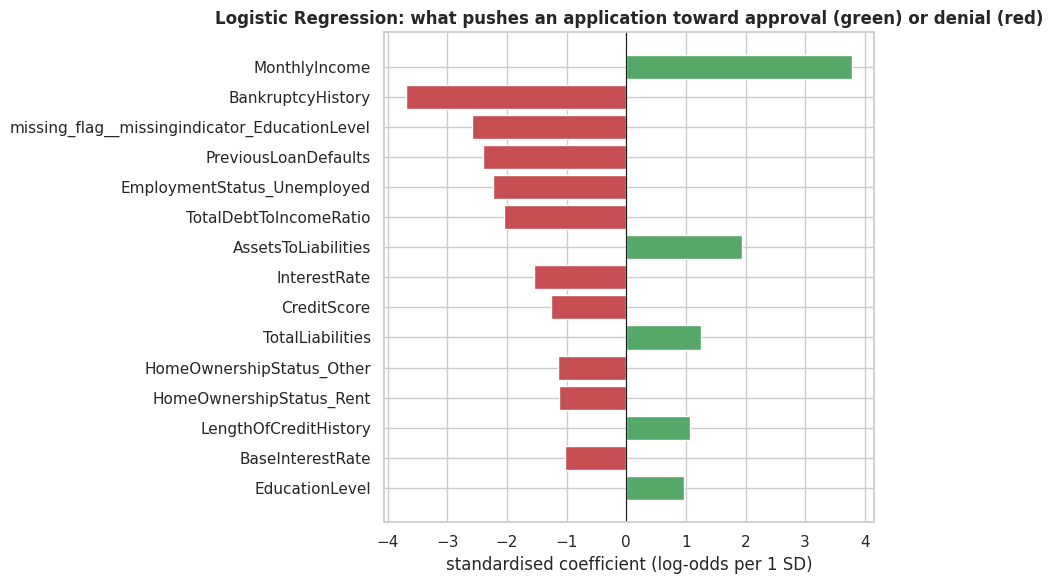

In [52]:
# ---------- Interpretable view: standardised coefficients of the tuned Logistic Regression ----------
lr_fit = clone(tuned_lr).fit(X_train, y_train)
feat_names = [n.replace('skewed__values__', '').replace('skewed__', '').replace('numeric__', '').replace('nominal__', '').replace('ordinal__level__', '').replace('ordinal__', '').replace('binary__', '') for n in lr_fit[:-1].get_feature_names_out()]
coefs = pd.Series(lr_fit.named_steps['model'].coef_[0], index=feat_names)
coef_tbl = pd.DataFrame({'coefficient (per 1 SD)': coefs, 'odds multiplier': np.exp(coefs)}).loc[coefs.abs().sort_values(ascending=False).index]
print(f'{(coefs != 0).sum()} of {len(coefs)} model features have non-zero coefficients')
display(coef_tbl.head(14).round(3))
fig, ax = plt.subplots(figsize=(9, 6)); c = coefs.loc[coefs.abs().sort_values(ascending=False).index[:15]].iloc[::-1]
ax.barh(c.index, c.values, color=np.where(c.values > 0, '#55a868', '#c44e52')); ax.axvline(0, color='k', lw=.8); ax.set_title('Logistic Regression: what pushes an application toward approval (green) or denial (red)'); ax.set_xlabel('standardised coefficient (log-odds per 1 SD)')
plt.tight_layout()


The logistic-regression benchmark gives the *direction* and size of each effect in plain terms (per one standard deviation, with log-scaled money fields): higher income (odds ×44), more assets relative to liabilities (×7) and a longer credit history (×2.9) raise approval odds; a bankruptcy (×0.03), a previous default (×0.09), unemployment (×0.11), a missing education level (×0.08), a higher total DTI (×0.13) and a higher interest rate (×0.21) lower them. The negative `CreditScore` coefficient looks odd but is a collinearity effect: the interest rate is built partly from the credit score, so once the rate is in the model the score adds a (partly offsetting) correction. Individual coefficients of correlated features should not be read in isolation. These explanations are what an adverse-action notice would draw on.

**Business recommendations from the importance results:** (1) income verification and the debt burden *after* the new loan are what matter, so invest in accurate income data (the 0.97 % corrupted incomes would otherwise affect decisions); (2) pricing (interest rate) is the second-strongest driver, so confirm it is set independently of the approval decision; (3) many data fields the bank collects (utilisation, inquiries, open lines, savings, tenure) add nothing and could be dropped from the application to reduce friction.

### 8h. Classification vs. regression: does the choice hold up?
The alternative framing (predict `RiskScore`, then approve if the predicted score is below a cut-off chosen on out-of-fold data) was fitted with a regularised linear model and a boosted regressor, with a predicted-vs-actual plot as requested for regression.


,CV RMSE,CV R2,CV MAE,CV ROC-AUC (as approval score),CV cost/appl @best cutoff ($),Test ROC-AUC,Test cost/appl ($)
Approach,,,,,,,
Regression: Ridge Regression,3.403,0.808,2.717,0.902,1518.375,0.900,1522.5
Regression: Hist Gradient Boosting Regressor,2.352,0.908,1.503,0.930,1348.000,0.932,1298.5
Classification: Tuned Logistic Regression,NaN,NaN,NaN,0.988,677.000,NaN,NaN
Classification: Tuned Hist Gradient Boosting,NaN,NaN,NaN,0.994,557.750,NaN,NaN
Classification: Ensemble (tuned LR + tuned HGB),NaN,NaN,NaN,0.993,573.375,NaN,NaN


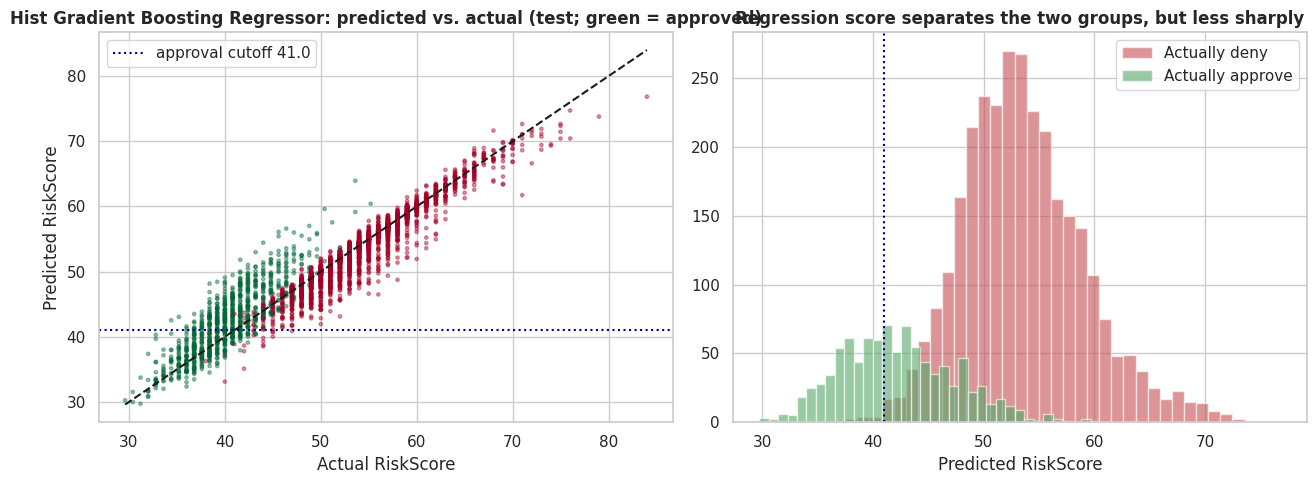

In [53]:
# ---------- Alternative framing: REGRESSION on RiskScore, then turn the predicted score into a decision ----------
# Caveat (see EDA): RiskScore already encodes the decision, so this is an upper-bound illustration of the regression route, not a clean benchmark.
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_models = {'Ridge Regression': make_pipeline(Ridge(alpha=1.0), scale=True),
              'Hist Gradient Boosting Regressor': make_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False)}
cut_grid = np.arange(30, 62, 0.25)
def cutoff_cost(y_true, pred_risk, cut): return business_cost(y_true, (pred_risk <= cut).astype(int)) / len(y_true)    # approve when predicted risk is LOW
reg_rows = []; reg_store = {}
for name, reg in reg_models.items():
    oof_r = cross_val_predict(reg, X_train, risk_train, cv=kf)
    costs = np.array([cutoff_cost(y_train, oof_r, c) for c in cut_grid]); cut = cut_grid[costs.argmin()]
    reg.fit(X_train, risk_train); pr_test = reg.predict(X_test)
    reg_store[name] = (oof_r, pr_test, cut)
    reg_rows.append({'Approach': f'Regression: {name}', 'CV RMSE': np.sqrt(mean_squared_error(risk_train, oof_r)), 'CV R2': r2_score(risk_train, oof_r), 'CV MAE': mean_absolute_error(risk_train, oof_r),
                     'CV ROC-AUC (as approval score)': roc_auc_score(y_train, -oof_r), 'CV cost/appl @best cutoff ($)': costs.min(),
                     'Test ROC-AUC': roc_auc_score(y_t, -pr_test), 'Test cost/appl ($)': cutoff_cost(y_t, pr_test, cut)})
for name in fin_df.index:
    reg_rows.append({'Approach': f'Classification: {name}', 'CV ROC-AUC (as approval score)': fin_df.loc[name, 'ROC-AUC'], 'CV cost/appl @best cutoff ($)': fin_df.loc[name, 'Cost/appl @best ($)']})
reg_df = pd.DataFrame(reg_rows).set_index('Approach'); display(reg_df.round(3))
best_reg = min(reg_store, key=lambda k: cutoff_cost(y_train, reg_store[k][0], reg_store[k][2])); oof_r, pr_test, cut = reg_store[best_reg]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(risk_test, pr_test, s=6, alpha=.4, c=y_t, cmap='RdYlGn'); lim = [risk_test.min(), risk_test.max()]; ax[0].plot(lim, lim, 'k--'); ax[0].axhline(cut, color='navy', ls=':', label=f'approval cutoff {cut:.1f}')
ax[0].set_xlabel('Actual RiskScore'); ax[0].set_ylabel('Predicted RiskScore'); ax[0].set_title(f'{best_reg}: predicted vs. actual (test; green = approved)'); ax[0].legend()
ax[1].hist(pr_test[y_t == 0], bins=40, alpha=.6, color='#c44e52', label='Actually deny'); ax[1].hist(pr_test[y_t == 1], bins=40, alpha=.6, color='#55a868', label='Actually approve'); ax[1].axvline(cut, color='navy', ls=':')
ax[1].set_xlabel('Predicted RiskScore'); ax[1].set_title('Regression score separates the two groups, but less sharply'); ax[1].legend()
plt.tight_layout()


The best regression model predicts `RiskScore` well (CV R² = 0.91, RMSE 2.4 points), but turning the score into decisions is far worse: **test ROC-AUC 0.932 vs. 0.994 and cost $1,298 per applicant vs. $537** for classification (the linear regressor: 0.900 and $1,523). The regression route does not even meet the cost target (≤ $956). The scatter shows why: approved and denied applicants overlap heavily in score (approved up to 56, denied down to 39), so a single cut-off must trade many $50 k mistakes against $8 k ones. This is despite the regression target already containing decision information. Predicting the decision directly with a cost-aware threshold is the better fit for the business problem, which confirms the choice made in the Business Understanding section.


## Conclusion

### Executive summary (for business stakeholders)

**What we built.** A machine-learning model that reads an application and estimates the probability that it should be approved, plus a decision rule tuned to FinTech Innovations' actual costs: **$50,000 for approving a loan that defaults, $8,000 for turning away a good customer.**

**How well it works.** On 4,000 applications the model had never seen:
- It put the right applicants first: **ROC-AUC 0.994** (1.0 = perfect).
- Of the applicants it approves, **98.7 % are good loans** (10 bad approvals out of 760).
- It finds **78.5 % of the good applicants**; the rest are declined, which is the deliberate price of avoiding $50 k losses.
- Average cost of wrong decisions: **$537 per applicant**, vs. **$1,912** if everyone were denied and **$38,050** if everyone were approved. On 10,000 applications that is about **$13.75 M less loss than denying everyone**.
- Ranking quality is consistent across employment, education, age, income and credit-score groups; the model is more cautious with low-income applicants (it approves fewer of the good ones).

**What drives decisions.** Income, the interest rate charged, the debt burden *including* the new loan, and the loan size explain nearly everything. The credit score, utilisation, inquiries, savings balances and loan purpose add almost nothing.

**Recommendations**
1. **Deploy as decision support with a review band.** Auto-approve at P ≥ 0.81 (about 19 % of applicants), send P between 0.3 and 0.81 (about 8 %) to a loan officer, auto-deny below 0.3. Pilot first and measure the realised saving (between roughly $180 and $540 per applicant on this test set).
2. **Remove age and marital status** from the model now (cost: about $16 per applicant) and have compliance review education and experience, which can act as proxies.
3. **Fix the data capture:** store income as a number and reconcile annual vs. monthly income (about 1 % of rows disagree); find out why applications with no education level are *always* denied; stop using `RiskScore` as an input.
4. **Explain decisions:** generate adverse-action reasons from the logistic-regression benchmark (income, DTI, interest rate, bankruptcy, defaults, employment) and keep the boosted model for ranking.
5. **Re-tune the threshold whenever costs change.** For a calibrated model, approve when P > FP cost / (FP cost + FN cost) (currently 0.862; the data-driven value is 0.81).
6. **Monitor** approval rate, bad-loan rate, drift and segment performance monthly; retrain on real repayment outcomes as they accumulate.

### Limitations
- **The label is the historical approval decision, not observed default.** The model learns to reproduce past decisions (including their biases), and all dollar figures are relative to those decisions. Applicants who were denied have no repayment outcome ("reject inference" problem).
- **The data looks highly structured.** An AUC of 0.994 with a narrow credit-score range (343–712) and decisions that depend almost only on a few fields suggests rule-driven decisions or simulated data. Real-world accuracy against actual defaults will be lower.
- **Flat costs:** $8,000 and $50,000 are applied to every loan, but a $50 k loss is unlikely on a $5 k loan. Loan-specific costs would change the optimal threshold per applicant.
- **Small counts drive the dollar figures:** with only 10 bad approvals in the test set, one more or one fewer changes cost by $12.50 per applicant; segment results (e.g. age 60+, n = 198) are noisy.
- **`InterestRate` may not be known at decision time** and is the second most important feature; this needs confirming. A single random split was used (no time-based validation).

### Potential improvements and next steps
1. Retrain on real default / repayment labels and add reject inference.
2. Use loan-specific cost weights and re-optimise thresholds per segment where legally permitted.
3. Add monotonic constraints (income ↑, DTI ↓, bankruptcy ↓) to the boosting model for explainability, and use SHAP values for per-applicant reasons.
4. Calibrate probabilities (isotonic / Platt) and test stacking.
5. Validate on a time-based split and run a fair-lending review (adverse-impact tests with protected-class data held out of the model).
6. Pilot the three-way policy and monitor real reviewer decisions.
